<a href="https://colab.research.google.com/github/Jyothi-adithya/NTM-WEDM-Kerf_width-prediction/blob/main/WEDM_Kerf_Width_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 AI/ML-Based Prediction of Kerf Width in Wire EDM (WEDM)

**Project Title:** Development and Comparison of AI/ML Models for Predicting Kerf Width in Wire Electrical Discharge Machining (WEDM)

**Subject:** Non-Traditional Machining

**Author:** [Your Name] | **Roll No:** [Your Roll No] | **Date:** [Date]

---

> **⚠️ Data Integrity Notice:**
> This notebook uses a dataset combining **27 original experimental observations** and **18 synthetic interpolated observations**.
> Synthetic observations were created by mathematical interpolation between measured current levels with other parameters held constant.
> They are **NOT** additional physical machining experiments and are **NOT** treated as independent ground truth during validation.

---

## 📋 Table of Contents
1. [Project Introduction](#section1)
2. [Import Libraries](#section2)
3. [Upload and Load Dataset](#section3)
4. [Dataset Validation and Cleaning](#section4)
5. [Exploratory Data Analysis (EDA)](#section5)
6. [Prepare Training and Validation Data](#section6)
7. [Model Development](#section7)
8. [Hyperparameter Tuning](#section8)
9. [Evaluation Metrics](#section9)
10. [Model Comparison](#section10)
11. [Actual vs Predicted Kerf Width](#section11)
12. [Residual Analysis](#section12)
13. [Feature Importance and Interpretation](#section13)
14. [Predict Kerf Width for New Settings](#section14)
15. [Save Model and Results](#section15)
16. [Final Conclusion](#section16)

---
# Section 1: Project Introduction
<a id='section1'></a>

## 1.1 What is Wire EDM (WEDM)?

**Wire Electrical Discharge Machining (WEDM)** is a non-traditional machining process that uses a thin, electrically conductive wire (typically brass, 0.1–0.3 mm diameter) as a cutting tool. The wire never physically contacts the workpiece. Instead, material is removed by a series of rapid, controlled electrical sparks (discharges) that occur in a dielectric fluid (usually deionised water) between the wire and the conductive workpiece.

WEDM is particularly valuable for:
- Cutting **hard materials** (tool steel, titanium, carbides) that resist conventional machining.
- Producing **intricate 2D profiles**, dies, punches, and aerospace components.
- Achieving **tight dimensional tolerances** without mechanical cutting forces.

Key process parameters that control WEDM performance include:

| Parameter | Typical Range | Effect |
|---|---|---|
| Wire Feed Rate (mm/s) | 1–15 | Controls wire renewal speed |
| Voltage (V) | 40–100 V | Gap voltage driving discharge |
| Pulse ON Time (µs) | 0.5–10 µs | Duration of each spark |
| Pulse OFF Time (µs) | 5–50 µs | Rest time between sparks |
| Peak Current (A) | 1–20 A | Energy per discharge |

## 1.2 What is Kerf Width?

**Kerf width** is the width of the slot or cut created by the WEDM wire in the workpiece material (measured in millimetres). It is always larger than the wire diameter because the electrical sparks erode material from both sides of the wire, and the spark gap (overcut) adds material removal on each side.

Kerf width is a **critical quality metric** because:
1. It directly determines **dimensional accuracy** of the machined part.
2. A wider kerf wastes material.
3. Inconsistent kerf leads to assembly problems in precision components.

## 1.3 Why Use Machine Learning for Kerf-Width Prediction?

The relationships between WEDM parameters and kerf width are:
- **Non-linear** — small changes in pulse-ON time can have disproportionate effects.
- **Interactive** — the effect of peak current changes depending on pulse-ON time.
- **Difficult to model analytically** from first principles.

A trained ML model can:
- **Predict kerf width in real time** for any given parameter combination.
- **Reduce expensive trial-and-error experiments**.
- **Support CNC program planning** by estimating the cut slot width before machining begins.

## 1.4 Four Regression Algorithms Being Compared

| Algorithm | Type | Key Strength |
|---|---|---|
| **Random Forest (RF)** | Ensemble of decision trees | Robust, handles non-linearity, built-in feature importance |
| **XGBoost** | Gradient-boosted trees | Often high accuracy, handles interactions well |
| **Artificial Neural Network (ANN)** | Multi-layer perceptron | Can model complex non-linear relationships |
| **Support Vector Regression (SVR)** | Kernel-based regression | Effective in high-dimensional spaces, robust to outliers |

All four are compared on the **same experimental data** using the **same evaluation splits** to ensure a fair comparison.

## 1.5 Important Note on Dataset Composition

> This project uses **wire feed rate** as a process parameter (not wire tension, as sometimes specified in literature). The dataset was collected with wire feed rate as the control variable. Wire tension was not measured or recorded, and no wire-tension column has been fabricated. This difference from some published WEDM studies is acknowledged and documented here.

---
# Section 2: Import Libraries
<a id='section2'></a>

We import all required libraries for data handling, visualization, machine learning, and file operations. XGBoost is installed if not already present in the Colab environment.

In [ ]:
# ── Install XGBoost (Colab may not have the latest version) ──────────────────
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', 'xgboost>=1.7'])
print('XGBoost installation check complete.')

XGBoost installation check complete.


In [ ]:
# ── Standard library ─────────────────────────────────────────────────────────
import os
import json
import warnings
import datetime
import zipfile
from pathlib import Path

# ── Data handling ─────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd

# ── Visualization ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import seaborn as sns

# ── Scikit-learn: preprocessing ───────────────────────────────────────────────
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# ── Scikit-learn: model selection ─────────────────────────────────────────────
from sklearn.model_selection import (
    KFold, GroupKFold, cross_val_predict, GridSearchCV
)

# ── Scikit-learn: models ──────────────────────────────────────────────────────
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR

# ── XGBoost ───────────────────────────────────────────────────────────────────
from xgboost import XGBRegressor

# ── Scikit-learn: metrics ─────────────────────────────────────────────────────
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# ── Scikit-learn: inspection ──────────────────────────────────────────────────
from sklearn.inspection import permutation_importance

# ── Model persistence ─────────────────────────────────────────────────────────
import joblib

# ── Google Colab utilities ────────────────────────────────────────────────────
try:
    from google.colab import files as colab_files
    IN_COLAB = True
    print('Running inside Google Colab.')
except ImportError:
    IN_COLAB = False
    print('Not running in Colab — file upload will use a local path fallback.')

# ── Global settings ───────────────────────────────────────────────────────────
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
warnings.filterwarnings('ignore')

# ── Plot style ────────────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
})
sns.set_theme(style='whitegrid', palette='muted')

# ── Output directory ──────────────────────────────────────────────────────────
OUTPUT_DIR = Path('wedm_results')
OUTPUT_DIR.mkdir(exist_ok=True)

# ── RMSE helper (works across all sklearn versions) ───────────────────────────
def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

# ── Column definitions ────────────────────────────────────────────────────────
FEATURE_COLS = [
    'Wire_Feed_Rate_mm_s',
    'Voltage_V',
    'Pulse_ON_Time_us',
    'Pulse_OFF_Time_us',
    'Peak_Current_A'
]
TARGET_COL = 'Kerf_Width_mm'
TYPE_COL   = 'Data_Type'
ID_COL     = 'Experiment_No'
AUX_COL    = 'Surface_Roughness_um'   # output — NOT used as a feature
REQUIRED_COLS = FEATURE_COLS + [TARGET_COL, TYPE_COL]

print(f'Output directory: {OUTPUT_DIR.resolve()}')
print('\nAll libraries imported successfully.')
import sklearn
import xgboost
print(f'NumPy  : {np.__version__}')
print(f'Pandas : {pd.__version__}')
print(f'Sklearn: {sklearn.__version__}')
print(f'XGBoost: {xgboost.__version__}')

Running inside Google Colab.
Output directory: /content/wedm_results

All libraries imported successfully.
NumPy  : 2.1.3
Pandas : 2.2.3
Sklearn: 1.6.1
XGBoost: 3.4.1


---
# Section 3: Upload and Load Dataset
<a id='section3'></a>

Upload your file `WEDM_Real_and_Synthetic_Combined.csv` using the cell below.
If you are not in Colab, set `LOCAL_CSV_PATH` to the full path of your CSV file.

After upload the code automatically:
1. Detects the uploaded filename (so renaming the file does not break the notebook).
2. Validates all required columns.
3. Reports a comprehensive summary of the dataset.

In [ ]:
# ── Upload (Colab) or local fallback ──────────────────────────────────────────
LOCAL_CSV_PATH = ''   # ← set this if running outside Colab

if IN_COLAB:
    print('Please upload your CSV file using the dialog below...')
    uploaded = colab_files.upload()
    if not uploaded:
        raise FileNotFoundError(
            'No file was uploaded. Please re-run this cell and upload the CSV.')
    csv_path = list(uploaded.keys())[0]
    print(f'\nDetected uploaded file: "{csv_path}"')
else:
    if not LOCAL_CSV_PATH:
        raise ValueError(
            'Not in Colab and LOCAL_CSV_PATH is empty.\n'
            'Set LOCAL_CSV_PATH to the full path of your CSV file.')
    csv_path = LOCAL_CSV_PATH
    print(f'Using local file: "{csv_path}"')

# ── Load CSV ──────────────────────────────────────────────────────────────────
df_raw = pd.read_csv(csv_path)
print(f'\nDataset loaded: {df_raw.shape[0]} rows × {df_raw.shape[1]} columns.')

Please upload your CSV file using the dialog below...


Saving WEDM_Real_and_Synthetic_Combined.csv to WEDM_Real_and_Synthetic_Combined.csv

Detected uploaded file: "WEDM_Real_and_Synthetic_Combined.csv"

Dataset loaded: 45 rows × 9 columns.


In [ ]:
# ── Column names ──────────────────────────────────────────────────────────────
print('=== Column Names ===')
for i, col in enumerate(df_raw.columns, 1):
    print(f'  {i:2d}. {col}')

# ── Validate required columns ─────────────────────────────────────────────────
missing_cols = [c for c in REQUIRED_COLS if c not in df_raw.columns]
if missing_cols:
    raise KeyError(
        f'The following required columns are MISSING from the uploaded file:\n'
        f'  {missing_cols}\n'
        f'Please check your CSV and re-upload.')
print('\n✅ All required columns are present.')

# ── Data types ────────────────────────────────────────────────────────────────
print('\n=== Data Types ===')
print(df_raw.dtypes.to_string())

# ── First and last five rows ──────────────────────────────────────────────────
print('\n=== First 5 Rows ===')
display(df_raw.head())
print('\n=== Last 5 Rows ===')
display(df_raw.tail())

# ── Missing values ────────────────────────────────────────────────────────────
print('\n=== Missing Values per Column ===')
mv = df_raw.isnull().sum()
print(mv.to_string())
print(f'  Total missing values: {mv.sum()}')

# ── Duplicate rows ────────────────────────────────────────────────────────────
n_dups = df_raw.duplicated().sum()
print(f'\n=== Duplicate Rows ===')
print(f'  {n_dups} exact duplicate row(s) found.')

# ── Real vs Synthetic counts ──────────────────────────────────────────────────
print('\n=== Data Type Distribution ===')
print(df_raw[TYPE_COL].value_counts().to_string())

# ── Descriptive statistics ────────────────────────────────────────────────────
print('\n=== Descriptive Statistics ===')
display(df_raw.describe().round(4))

=== Column Names ===
   1. Experiment_No
   2. Wire_Feed_Rate_mm_s
   3. Voltage_V
   4. Pulse_ON_Time_us
   5. Pulse_OFF_Time_us
   6. Peak_Current_A
   7. Surface_Roughness_um
   8. Kerf_Width_mm
   9. Data_Type

✅ All required columns are present.

=== Data Types ===
Experiment_No           float64
Wire_Feed_Rate_mm_s     float64
Voltage_V               float64
Pulse_ON_Time_us        float64
Pulse_OFF_Time_us       float64
Peak_Current_A          float64
Surface_Roughness_um    float64
Kerf_Width_mm           float64
Data_Type                object

=== First 5 Rows ===


,Experiment_No,Wire_Feed_Rate_mm_s,Voltage_V,Pulse_ON_Time_us,Pulse_OFF_Time_us,Peak_Current_A,Surface_Roughness_um,Kerf_Width_mm,Data_Type
0,1.0,30.0,40.0,7.0,10.0,2.0,2.900,0.186,Real
1,2.0,30.0,40.0,7.0,10.0,3.0,2.265,0.194,Real
2,3.0,30.0,40.0,7.0,10.0,4.0,2.533,0.195,Real
3,4.0,30.0,50.0,8.0,11.0,2.0,1.760,0.200,Real
4,5.0,30.0,50.0,8.0,11.0,3.0,2.002,0.171,Real



=== Last 5 Rows ===


,Experiment_No,Wire_Feed_Rate_mm_s,Voltage_V,Pulse_ON_Time_us,Pulse_OFF_Time_us,Peak_Current_A,Surface_Roughness_um,Kerf_Width_mm,Data_Type
40,NaN,50.0,40.0,9.0,11.0,3.5,3.2155,0.3240,Synthetic_Interpolated
41,NaN,50.0,50.0,7.0,12.0,2.5,4.4955,0.0715,Synthetic_Interpolated
42,NaN,50.0,50.0,7.0,12.0,3.5,3.3010,0.1115,Synthetic_Interpolated
43,NaN,50.0,60.0,8.0,10.0,2.5,4.0930,0.1970,Synthetic_Interpolated
44,NaN,50.0,60.0,8.0,10.0,3.5,3.4015,0.1915,Synthetic_Interpolated



=== Missing Values per Column ===
Experiment_No           18
Wire_Feed_Rate_mm_s      0
Voltage_V                0
Pulse_ON_Time_us         0
Pulse_OFF_Time_us        0
Peak_Current_A           0
Surface_Roughness_um     0
Kerf_Width_mm            0
Data_Type                0
  Total missing values: 18

=== Duplicate Rows ===
  0 exact duplicate row(s) found.

=== Data Type Distribution ===
Data_Type
Real                      27
Synthetic_Interpolated    18

=== Descriptive Statistics ===


,Experiment_No,Wire_Feed_Rate_mm_s,Voltage_V,Pulse_ON_Time_us,Pulse_OFF_Time_us,Peak_Current_A,Surface_Roughness_um,Kerf_Width_mm
count,27.0000,45.0000,45.0000,45.0000,45.0000,45.0000,45.0000,45.0000
mean,14.0000,40.0000,50.0000,8.0000,11.0000,3.0000,2.8721,0.1870
std,7.9373,8.2572,8.2572,0.8257,0.8257,0.7151,0.8883,0.0846
min,1.0000,30.0000,40.0000,7.0000,10.0000,2.0000,1.7600,0.0700
25%,7.5000,30.0000,40.0000,7.0000,10.0000,2.5000,2.2520,0.1410
50%,14.0000,40.0000,50.0000,8.0000,11.0000,3.0000,2.5330,0.1900
75%,20.5000,50.0000,60.0000,9.0000,12.0000,3.5000,3.4000,0.1970
max,27.0000,50.0000,60.0000,9.0000,12.0000,4.0000,5.0760,0.5130


---
# Section 4: Dataset Validation and Cleaning
<a id='section4'></a>

We inspect the dataset for:
- **Missing values** — will prevent model training.
- **Duplicate rows** — may inflate validation scores.
- **Non-numeric values** — must be converted or removed.
- **Impossible values** (negative kerf width, zero voltage, etc.) — physically invalid.
- **Statistical outliers** — flagged for investigation, NOT automatically deleted.

> ⚠️ An observation is only removed if it is physically impossible or demonstrably erroneous. Statistical outliers in a small dataset of 27 experiments may represent genuine extreme-condition results and are preserved unless there is a specific documented reason for removal.

In [ ]:
# ── Work on a copy ────────────────────────────────────────────────────────────
df = df_raw.copy()

print('=' * 60)
print('DATASET VALIDATION REPORT')
print('=' * 60)

# 1. Enforce numeric types
numeric_cols = FEATURE_COLS + [TARGET_COL]
if AUX_COL in df.columns:
    numeric_cols.append(AUX_COL)

for col in numeric_cols:
    before_nulls = df[col].isnull().sum()
    df[col] = pd.to_numeric(df[col], errors='coerce')
    after_nulls = df[col].isnull().sum()
    n_coerced = after_nulls - before_nulls
    if n_coerced > 0:
        print(f'  WARNING: "{col}": {n_coerced} non-numeric value(s) coerced to NaN.')

# 2. Missing values (post-coercion)
print('\n[1] Missing Values (post numeric coercion):')
mv_post = df[FEATURE_COLS + [TARGET_COL]].isnull().sum()
if mv_post.sum() == 0:
    print('    ✅ No missing values detected.')
else:
    print(mv_post[mv_post > 0].to_string())
    rows_before = len(df)
    df.dropna(subset=FEATURE_COLS + [TARGET_COL], inplace=True)
    print(f'    → Dropped {rows_before - len(df)} row(s) with missing feature/target values.')

# 3. Duplicate rows
print('\n[2] Duplicate Rows:')
dup_mask = df.duplicated(subset=FEATURE_COLS + [TARGET_COL], keep=False)
n_dups = dup_mask.sum()
if n_dups == 0:
    print('    ✅ No exact duplicate rows in feature+target space.')
else:
    print(f'    ⚠️  {n_dups} row(s) are exact duplicates in feature+target space.')
    print('    Retained — each may correspond to a separate physical run.')

# 4. Physical plausibility checks
print('\n[3] Physical Plausibility Checks:')
checks = [
    ('Wire_Feed_Rate_mm_s', 0,   50,  'mm/s'),
    ('Voltage_V',           10,  500, 'V'   ),
    ('Pulse_ON_Time_us',    0,   500, 'µs'  ),
    ('Pulse_OFF_Time_us',   0,   500, 'µs'  ),
    ('Peak_Current_A',      0,   50,  'A'   ),
    ('Kerf_Width_mm',       0,   5,   'mm'  ),
]
for col, lo, hi, unit in checks:
    if col not in df.columns:
        continue
    out_of_range = (df[col] < lo) | (df[col] > hi)
    if out_of_range.any():
        print(f'    ⚠️  "{col}": {out_of_range.sum()} value(s) outside [{lo}, {hi}] {unit} — FLAGGED')
    else:
        print(f'    ✅  "{col}": all values within [{lo}, {hi}] {unit}')

# Remove physically impossible kerf width ≤ 0
zero_kerf = df[TARGET_COL] <= 0
if zero_kerf.any():
    print(f'    ❌  Kerf width ≤ 0 mm: {zero_kerf.sum()} row(s) — physically impossible — REMOVED.')
    df = df[~zero_kerf]

# 5. Statistical outlier detection (IQR — flag only)
print('\n[4] Statistical Outlier Detection (IQR, flagging only — NOT removed):')
for col in FEATURE_COLS + [TARGET_COL]:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    outlier_mask = (df[col] < Q1 - 1.5 * IQR) | (df[col] > Q3 + 1.5 * IQR)
    if outlier_mask.any():
        print(f'    ⚠️  "{col}": {outlier_mask.sum()} statistical outlier(s) — retained for investigation.')
    else:
        print(f'    ✅  "{col}": no statistical outliers.')

# 6. Range summary
print('\n[5] Feature and Target Ranges (final usable dataset):')
range_df = pd.DataFrame({
    'Min':  df[FEATURE_COLS + [TARGET_COL]].min(),
    'Max':  df[FEATURE_COLS + [TARGET_COL]].max(),
    'Mean': df[FEATURE_COLS + [TARGET_COL]].mean().round(4),
    'Std':  df[FEATURE_COLS + [TARGET_COL]].std().round(4),
})
display(range_df)

# 7. Final record summary
print('\n[6] Final Record Summary:')
print(f'    Total usable rows      : {len(df)}')
print(f'    Real experimental      : {(df[TYPE_COL]=="Real").sum()}')
print(f'    Synthetic interpolated : {(df[TYPE_COL]=="Synthetic_Interpolated").sum()}')
print('\n✅ Validation complete. Dataset is ready for analysis.')

DATASET VALIDATION REPORT

[1] Missing Values (post numeric coercion):
    ✅ No missing values detected.

[2] Duplicate Rows:
    ✅ No exact duplicate rows in feature+target space.

[3] Physical Plausibility Checks:
    ✅  "Wire_Feed_Rate_mm_s": all values within [0, 50] mm/s
    ✅  "Voltage_V": all values within [10, 500] V
    ✅  "Pulse_ON_Time_us": all values within [0, 500] µs
    ✅  "Pulse_OFF_Time_us": all values within [0, 500] µs
    ✅  "Peak_Current_A": all values within [0, 50] A
    ✅  "Kerf_Width_mm": all values within [0, 5] mm

[4] Statistical Outlier Detection (IQR, flagging only — NOT removed):
    ✅  "Wire_Feed_Rate_mm_s": no statistical outliers.
    ✅  "Voltage_V": no statistical outliers.
    ✅  "Pulse_ON_Time_us": no statistical outliers.
    ✅  "Pulse_OFF_Time_us": no statistical outliers.
    ✅  "Peak_Current_A": no statistical outliers.
    ⚠️  "Kerf_Width_mm": 4 statistical outlier(s) — retained for investigation.

[5] Feature and Target Ranges (final usable da

,Min,Max,Mean,Std
Wire_Feed_Rate_mm_s,30.00,50.000,40.000,8.2572
Voltage_V,40.00,60.000,50.000,8.2572
Pulse_ON_Time_us,7.00,9.000,8.000,0.8257
Pulse_OFF_Time_us,10.00,12.000,11.000,0.8257
Peak_Current_A,2.00,4.000,3.000,0.7151
Kerf_Width_mm,0.07,0.513,0.187,0.0846



[6] Final Record Summary:
    Total usable rows      : 45
    Real experimental      : 27
    Synthetic interpolated : 18

✅ Validation complete. Dataset is ready for analysis.


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=range_df)

https://docs.google.com/spreadsheets/d/1Aqjn_-BfQSuwaio4E-u7lBmMK9loWnuEGQDidHaqTds/edit#gid=0


In [ ]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=range_df)

https://docs.google.com/spreadsheets/d/1OGfHFq6jDHN1gVCltxJYe3tyLVALZ059rhtIO62tHjA/edit#gid=0


---
# Section 5: Exploratory Data Analysis (EDA)
<a id='section5'></a>

EDA helps us understand the structure, distributions, and relationships in the data **before** building models.

> **Reminder:** Correlation coefficients describe **statistical association** — they do not prove causation.

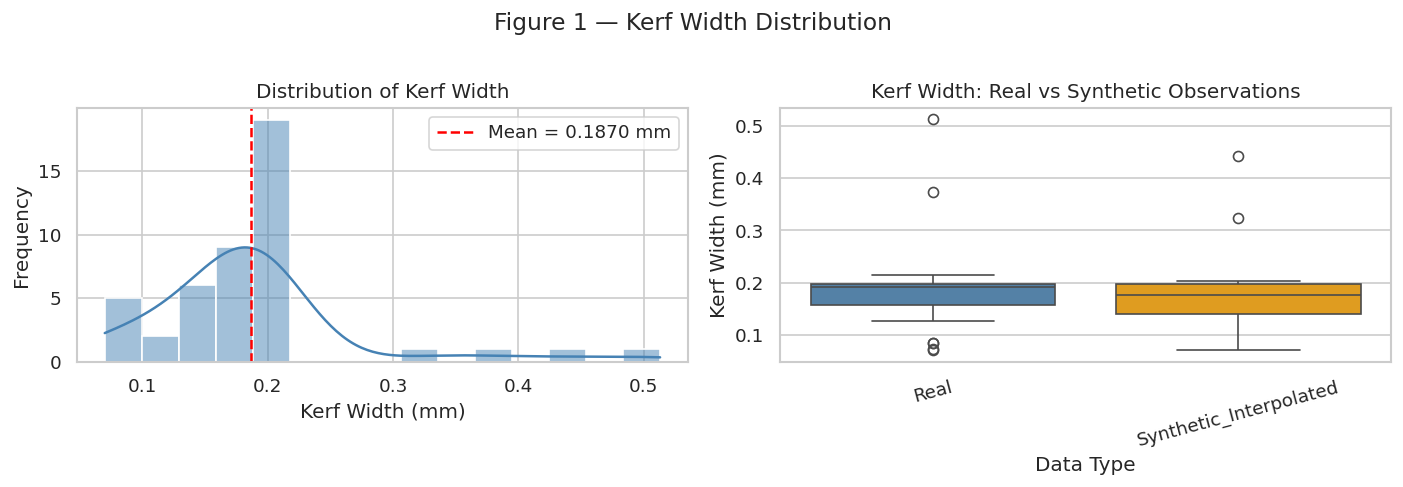

Figure 1 — The histogram shows the spread of kerf width values across all rows.
The box plots compare the distribution between real and synthetic observations.


In [ ]:
# ── Units for labelling ───────────────────────────────────────────────────────
UNITS = ['mm/s', 'V', 'µs', 'µs', 'A']
PALETTE = {'Real': 'steelblue', 'Synthetic_Interpolated': 'orange'}

# ── Figure 1: Kerf Width Distribution ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET_COL], bins=15, kde=True, ax=axes[0], color='steelblue')
mean_kw = df[TARGET_COL].mean()
axes[0].axvline(mean_kw, color='red', linestyle='--', label=f'Mean = {mean_kw:.4f} mm')
axes[0].set_title('Distribution of Kerf Width')
axes[0].set_xlabel('Kerf Width (mm)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

sns.boxplot(data=df, x=TYPE_COL, y=TARGET_COL, ax=axes[1], palette=PALETTE)
axes[1].set_title('Kerf Width: Real vs Synthetic Observations')
axes[1].set_xlabel('Data Type')
axes[1].set_ylabel('Kerf Width (mm)')
axes[1].tick_params(axis='x', rotation=15)
plt.suptitle('Figure 1 — Kerf Width Distribution', fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig1_kerf_distribution.png', bbox_inches='tight')
plt.show()
print('Figure 1 — The histogram shows the spread of kerf width values across all rows.')
print('The box plots compare the distribution between real and synthetic observations.')

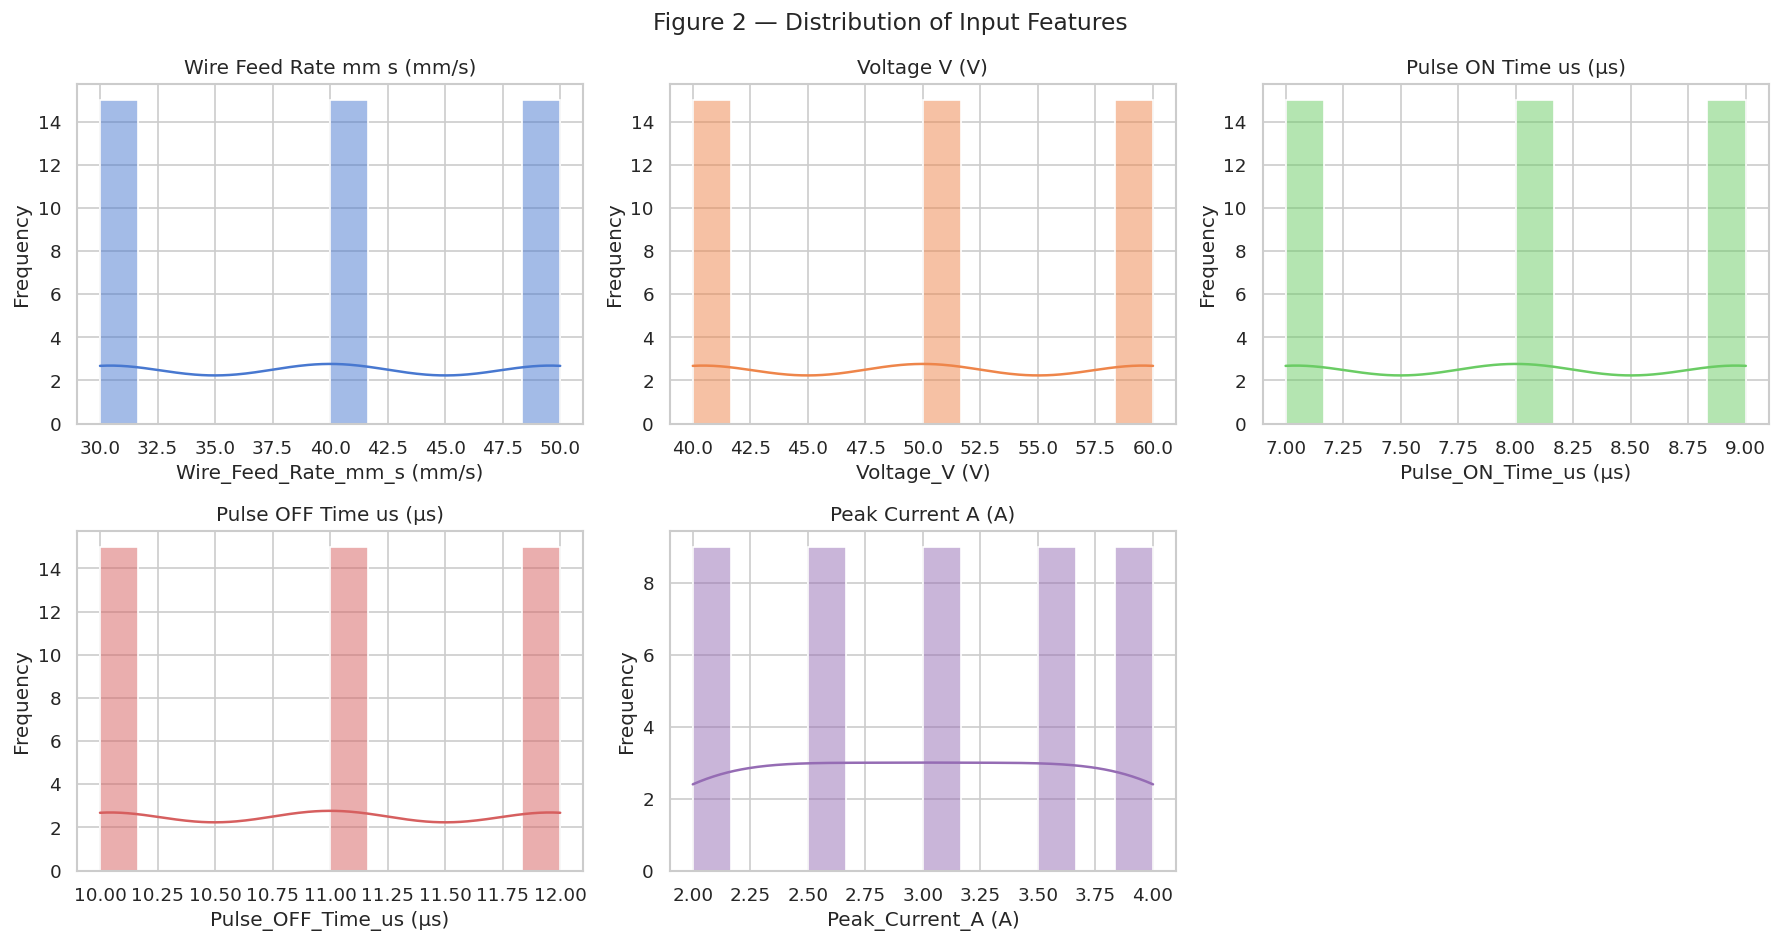

Figure 2 — Uniform/near-uniform distributions suggest a designed experiment (DOE).


In [ ]:
# ── Figure 2: Distribution of Each Input Feature ──────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, (col, unit) in enumerate(zip(FEATURE_COLS, UNITS)):
    sns.histplot(df[col], bins=12, kde=True, ax=axes[i],
                 color=sns.color_palette('muted')[i])
    axes[i].set_title(f'{col.replace("_", " ")} ({unit})')
    axes[i].set_xlabel(f'{col} ({unit})')
    axes[i].set_ylabel('Frequency')
axes[-1].set_visible(False)
plt.suptitle('Figure 2 — Distribution of Input Features', fontsize=14)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig2_feature_distributions.png', bbox_inches='tight')
plt.show()
print('Figure 2 — Uniform/near-uniform distributions suggest a designed experiment (DOE).')

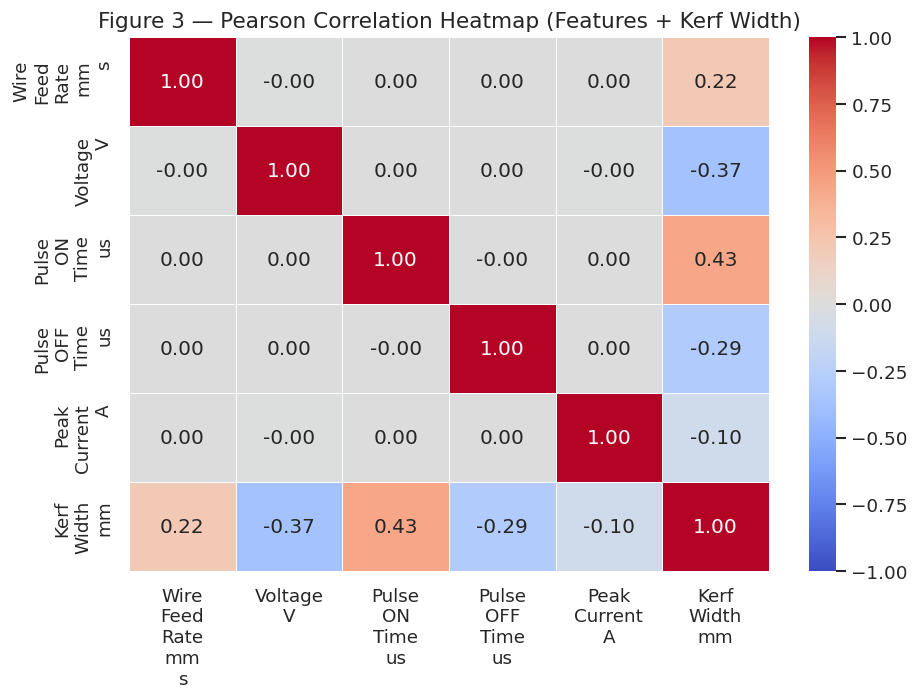

Figure 3 — Values near ±1 indicate strong linear association.
Note: zero Pearson correlation does NOT rule out a non-linear relationship.


In [ ]:
# ── Figure 3: Correlation Heatmap ─────────────────────────────────────────────
corr_cols = FEATURE_COLS + [TARGET_COL]
corr_matrix = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
    vmin=-1, vmax=1, ax=ax, linewidths=0.5,
    xticklabels=[c.replace('_', '\n') for c in corr_cols],
    yticklabels=[c.replace('_', '\n') for c in corr_cols]
)
ax.set_title('Figure 3 — Pearson Correlation Heatmap (Features + Kerf Width)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig3_correlation_heatmap.png', bbox_inches='tight')
plt.show()
print('Figure 3 — Values near ±1 indicate strong linear association.')
print('Note: zero Pearson correlation does NOT rule out a non-linear relationship.')

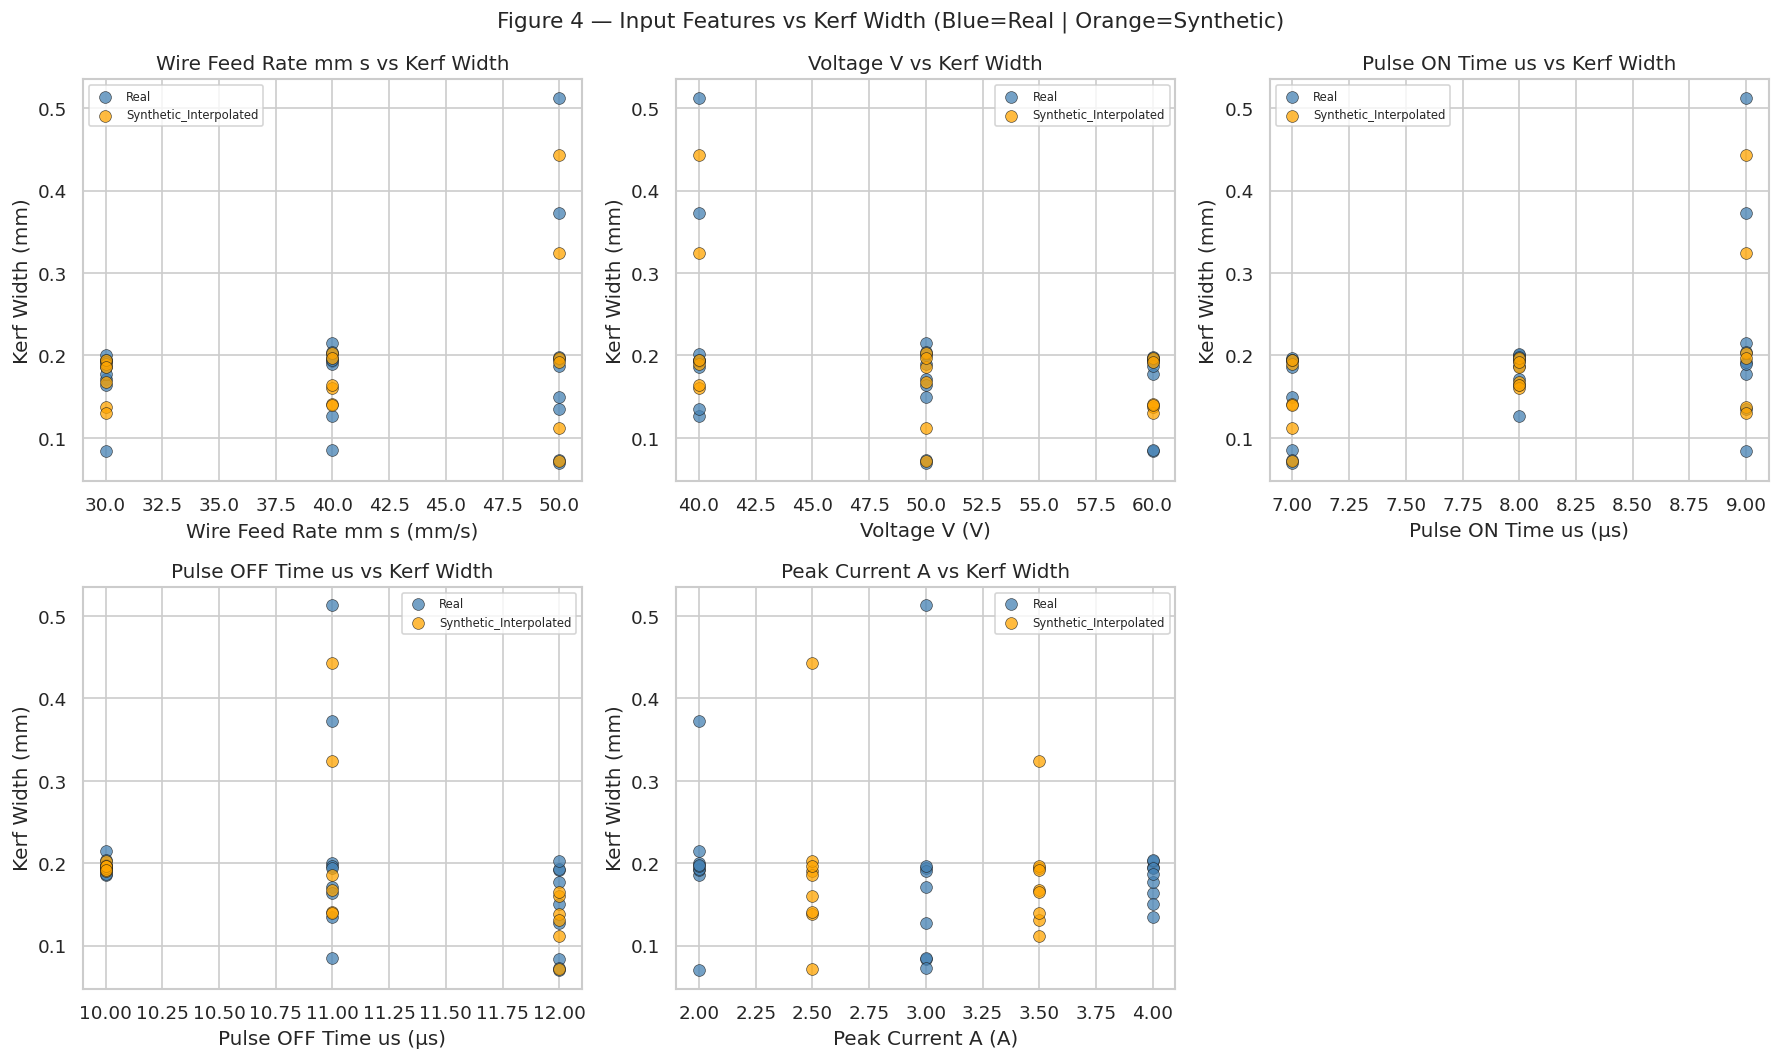

Figure 4 — A rising trend indicates a positive association; scatter around any trend
shows that kerf width depends on multiple parameters simultaneously.


In [ ]:
# ── Figure 4: Scatter Plots — Features vs Kerf Width ─────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()
for i, (col, unit) in enumerate(zip(FEATURE_COLS, UNITS)):
    for dtype, grp in df.groupby(TYPE_COL):
        axes[i].scatter(
            grp[col], grp[TARGET_COL],
            label=dtype, alpha=0.75, s=50,
            color=PALETTE.get(dtype, 'grey'),
            edgecolors='k', linewidths=0.4
        )
    axes[i].set_xlabel(f'{col.replace("_", " ")} ({unit})')
    axes[i].set_ylabel('Kerf Width (mm)')
    axes[i].set_title(f'{col.replace("_", " ")} vs Kerf Width')
    axes[i].legend(fontsize=7)
axes[-1].set_visible(False)
plt.suptitle('Figure 4 — Input Features vs Kerf Width (Blue=Real | Orange=Synthetic)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig4_scatter_features_vs_kerf.png', bbox_inches='tight')
plt.show()
print('Figure 4 — A rising trend indicates a positive association; scatter around any trend')
print('shows that kerf width depends on multiple parameters simultaneously.')

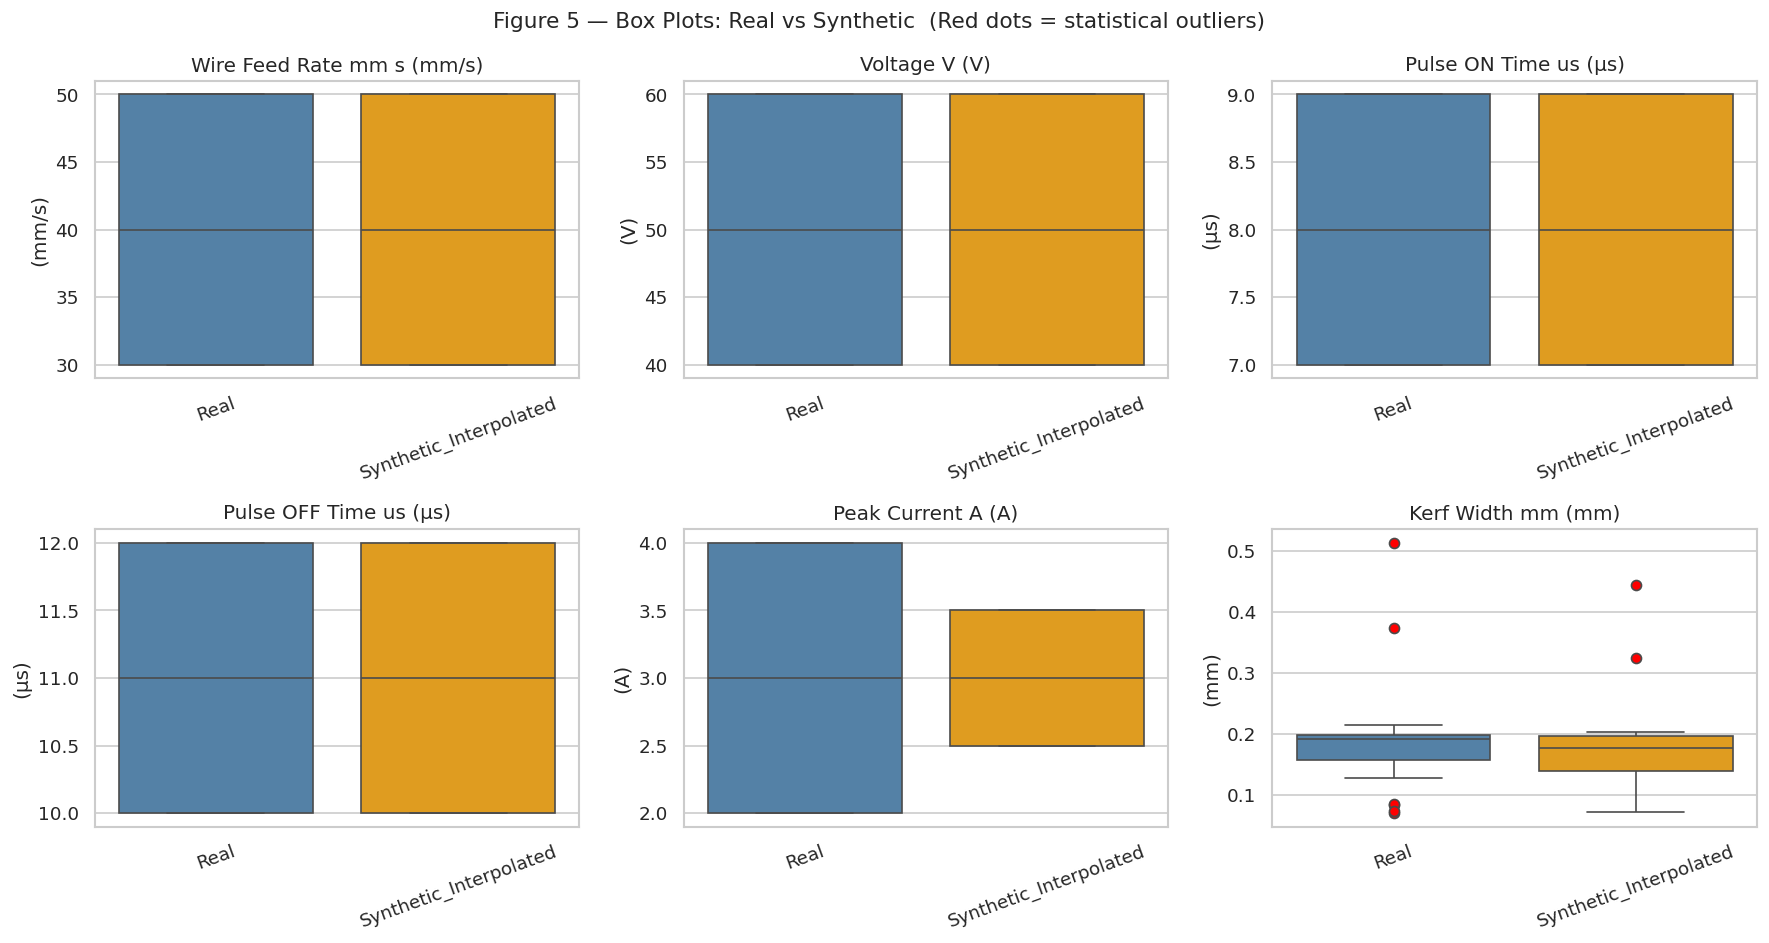

Figure 5 — Red dots are IQR-based statistical outliers. They are flagged but retained.


In [ ]:
# ── Figure 5: Box Plots (outlier inspection) ──────────────────────────────────
all_plot_cols = FEATURE_COLS + [TARGET_COL]
all_units     = UNITS + ['mm']
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()
for i, (col, unit) in enumerate(zip(all_plot_cols, all_units)):
    sns.boxplot(
        data=df, x=TYPE_COL, y=col, ax=axes[i], palette=PALETTE,
        flierprops=dict(marker='o', markerfacecolor='red', markersize=6)
    )
    axes[i].set_title(f'{col.replace("_", " ")} ({unit})')
    axes[i].set_xlabel('')
    axes[i].set_ylabel(f'({unit})')
    axes[i].tick_params(axis='x', rotation=20)
plt.suptitle('Figure 5 — Box Plots: Real vs Synthetic  (Red dots = statistical outliers)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig5_boxplots.png', bbox_inches='tight')
plt.show()
print('Figure 5 — Red dots are IQR-based statistical outliers. They are flagged but retained.')

---
# Section 6: Prepare Training and Validation Data
<a id='section6'></a>

## ⚠️ Critical Scientific Design Issue

The dataset mixes **27 real experimental rows** and **18 synthetic rows** derived from those real rows (by interpolating Peak Current while holding the other four parameters fixed). A random 80/20 split of all 45 rows risks placing a synthetic row in the test set while its parent real row is in training — a form of **data leakage** producing artificially optimistic metrics.

### Two Defensible Experiments

| Experiment | Data | Evaluation Strategy |
|---|---|---|
| **A — Real-data baseline** | 27 real rows only | 5-fold CV, out-of-fold predictions |
| **B — Real + Synthetic** | All 45 rows in training folds | GroupKFold — related rows kept together; metrics on real held-out rows only |

### Grouping Logic (Experiment B)
Rows sharing the same `Wire_Feed_Rate`, `Voltage`, `Pulse_ON_Time`, and `Pulse_OFF_Time` form one **group**. `GroupKFold` ensures that all rows in a group (real + its synthetic derivatives) appear only in training **or** only in validation — never split across both.

In [ ]:
# ── Separate real and full datasets ──────────────────────────────────────────
df_real = df[df[TYPE_COL] == 'Real'].copy().reset_index(drop=True)
df_full = df.copy().reset_index(drop=True)

X_real = df_real[FEATURE_COLS].values
y_real = df_real[TARGET_COL].values

X_full = df_full[FEATURE_COLS].values
y_full = df_full[TARGET_COL].values

print(f'Real observations : {len(df_real)} rows')
print(f'All observations  : {len(df_full)} rows')

# ── Experiment A: 5-fold CV on real data ─────────────────────────────────────
N_FOLDS_A = 5
kf_A = KFold(n_splits=N_FOLDS_A, shuffle=True, random_state=RANDOM_SEED)
print(f'\nExperiment A: {N_FOLDS_A}-fold CV on {len(df_real)} real rows.')
print('  ⚠️  With only 27 observations, CV estimates carry considerable uncertainty.')

# ── Experiment B: GroupKFold on all 45 rows ───────────────────────────────────
group_cols = ['Wire_Feed_Rate_mm_s', 'Voltage_V', 'Pulse_ON_Time_us', 'Pulse_OFF_Time_us']
df_full['_group'] = df_full.groupby(group_cols).ngroup()
groups_full = df_full['_group'].values
n_unique_groups = df_full['_group'].nunique()

N_FOLDS_B = min(5, n_unique_groups)
gkf_B = GroupKFold(n_splits=N_FOLDS_B)

print(f'\nExperiment B: {N_FOLDS_B}-fold GroupKFold on {len(df_full)} rows.')
print(f'  Unique parameter groups: {n_unique_groups}')
print('  Metrics will be computed on REAL held-out rows only.')
print('  Synthetic rows in the validation fold are EXCLUDED from metric computation.')

# ── Group composition summary ─────────────────────────────────────────────────
print('\nGroup composition (first 8 groups):')
grp_summary = df_full.groupby('_group').agg(
    n_real   = pd.NamedAgg(column=TYPE_COL, aggfunc=lambda x: (x=='Real').sum()),
    n_synth  = pd.NamedAgg(column=TYPE_COL, aggfunc=lambda x: (x=='Synthetic_Interpolated').sum()),
    n_total  = (TYPE_COL, 'count')
).reset_index()
display(grp_summary.head(8))

# Boolean mask to identify real rows in the full dataset
real_mask_full = (df_full[TYPE_COL] == 'Real').values

Real observations : 27 rows
All observations  : 45 rows

Experiment A: 5-fold CV on 27 real rows.
  ⚠️  With only 27 observations, CV estimates carry considerable uncertainty.

Experiment B: 5-fold GroupKFold on 45 rows.
  Unique parameter groups: 9
  Metrics will be computed on REAL held-out rows only.
  Synthetic rows in the validation fold are EXCLUDED from metric computation.

Group composition (first 8 groups):


,_group,n_real,n_synth,n_total
0,0,3,2,5
1,1,3,2,5
2,2,3,2,5
3,3,3,2,5
4,4,3,2,5
5,5,3,2,5
6,6,3,2,5
7,7,3,2,5


---
# Section 7: Model Development
<a id='section7'></a>

Four regression models are built as **scikit-learn Pipelines** so preprocessing is always fitted on training data only (preventing leakage).

| Model | Preprocessing in Pipeline |
|---|---|
| Random Forest | None (tree-based) |
| XGBoost | None (tree-based) |
| ANN (MLP) | StandardScaler |
| SVR | StandardScaler |

In [ ]:
# ── Model builder functions ───────────────────────────────────────────────────

def build_rf():
    """Random Forest — no scaling needed for tree-based models."""
    return Pipeline([('model', RandomForestRegressor(
        n_estimators=200, max_features='sqrt', min_samples_leaf=2,
        random_state=RANDOM_SEED, n_jobs=-1
    ))])

def build_xgb():
    """XGBoost — conservative regularization to reduce overfitting on small data."""
    return Pipeline([('model', XGBRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=3,
        subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0,
        random_state=RANDOM_SEED, verbosity=0, eval_metric='rmse'
    ))])

def build_ann():
    """ANN (MLP) — small architecture suitable for ~27 observations."""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('model',  MLPRegressor(
            hidden_layer_sizes=(32, 16), activation='relu',
            solver='lbfgs', max_iter=2000,
            alpha=0.01, random_state=RANDOM_SEED
        ))
    ])

def build_svr():
    """SVR with RBF kernel — requires StandardScaler."""
    return Pipeline([
        ('scaler', StandardScaler()),
        ('model',  SVR(kernel='rbf', C=10, epsilon=0.005, gamma='scale'))
    ])

MODEL_BUILDERS = {
    'Random Forest': build_rf,
    'XGBoost':       build_xgb,
    'ANN':           build_ann,
    'SVR':           build_svr,
}
print('Model builder functions defined:')
for name in MODEL_BUILDERS:
    print(f'  ✅  {name}')

Model builder functions defined:
  ✅  Random Forest
  ✅  XGBoost
  ✅  ANN
  ✅  SVR


---
# Section 8: Hyperparameter Tuning
<a id='section8'></a>

With only 27 real observations, nested cross-validation for tuning is statistically unstable. We use a simple, transparent approach:

- **3-fold inner CV** on all 27 real rows.
- **Modest parameter grids** — avoid over-parameterisation.
- Outer evaluation splits (Section 9) remain completely untouched.

> ⚠️ **Limitation:** With 27 rows and 3-fold inner CV each inner training fold has ~18 rows. Hyperparameter estimates have high variance and should be treated as reasonable starting points, not precision-optimised settings.

In [ ]:
inner_cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)

param_grids = {
    'Random Forest': {
        'model__n_estimators':     [100, 200, 300],
        'model__max_features':     ['sqrt', 'log2'],
        'model__min_samples_leaf': [1, 2, 3],
    },
    'XGBoost': {
        'model__n_estimators':  [100, 200],
        'model__learning_rate': [0.05, 0.1],
        'model__max_depth':     [2, 3, 4],
        'model__reg_alpha':     [0.0, 0.1],
    },
    'ANN': {
        'model__hidden_layer_sizes': [(32, 16), (64, 32), (32,)],
        'model__alpha':              [0.001, 0.01, 0.1],
    },
    'SVR': {
        'model__C':       [1, 10, 50, 100],
        'model__epsilon': [0.001, 0.005, 0.01],
        'model__gamma':   ['scale', 'auto'],
    },
}

best_params  = {}
tuned_models = {}

print('Hyperparameter tuning (3-fold inner CV on 27 real rows)...')
print('Please wait — this may take 1-2 minutes.\n')

for name, builder in MODEL_BUILDERS.items():
    pipeline = builder()
    gs = GridSearchCV(
        pipeline,
        param_grid=param_grids[name],
        cv=inner_cv,
        scoring='neg_root_mean_squared_error',
        n_jobs=-1,
        refit=True
    )
    gs.fit(X_real, y_real)
    best_params[name]  = gs.best_params_
    tuned_models[name] = gs.best_estimator_
    print(f'  [{name}]')
    print(f'    Best params : {gs.best_params_}')
    print(f'    Best CV RMSE: {-gs.best_score_:.6f} mm\n')

print('Tuning complete.')
print('⚠️  tuned_models are fitted on ALL real data — use Section 9 CV loop for unbiased metrics.')

Hyperparameter tuning (3-fold inner CV on 27 real rows)...
Please wait — this may take 1-2 minutes.

  [Random Forest]
    Best params : {'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
    Best CV RMSE: 0.071222 mm

  [XGBoost]
    Best params : {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 100, 'model__reg_alpha': 0.1}
    Best CV RMSE: 0.074605 mm

  [ANN]
    Best params : {'model__alpha': 0.1, 'model__hidden_layer_sizes': (32, 16)}
    Best CV RMSE: 0.081262 mm

  [SVR]
    Best params : {'model__C': 1, 'model__epsilon': 0.01, 'model__gamma': 'scale'}
    Best CV RMSE: 0.083948 mm

Tuning complete.
⚠️  tuned_models are fitted on ALL real data — use Section 9 CV loop for unbiased metrics.


---
# Section 9: Evaluation Metrics
<a id='section9'></a>

### Metrics

| Metric | Formula | Direction |
|---|---|---|
| **R²** | $1 - \frac{\sum(y_i - \hat{y}_i)^2}{\sum(y_i - \bar{y})^2}$ | Higher is better |
| **RMSE** | $\sqrt{\frac{1}{n}\sum(y_i - \hat{y}_i)^2}$ mm | Lower is better |
| **MAE** | $\frac{1}{n}\sum|y_i - \hat{y}_i|$ mm | Lower is better |

> R² **can be negative** when predictions are worse than simply predicting the mean — common with very small datasets or poor model fits.

All metrics are computed from **out-of-fold (OOF) predictions** — each observation is predicted only by a model that was **not** trained on it.

In [ ]:
# ── Helper functions ──────────────────────────────────────────────────────────

def build_tuned_pipeline(name):
    """Fresh pipeline with tuned hyperparameters."""
    p = MODEL_BUILDERS[name]()
    p.set_params(**best_params[name])
    return p

def calc_metrics(y_true, y_pred, label=''):
    r2  = r2_score(y_true, y_pred)
    rms = rmse(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    if label:
        print(f'    R²   = {r2:+.4f}')
        print(f'    RMSE = {rms:.6f} mm')
        print(f'    MAE  = {mae:.6f} mm')
    return {'R2': r2, 'RMSE_mm': rms, 'MAE_mm': mae}

# ═══════════════════════════════════════════════════════════════════
# EXPERIMENT A — 5-fold CV on 27 real rows
# ═══════════════════════════════════════════════════════════════════
print('=' * 60)
print('EXPERIMENT A: 5-Fold CV on 27 Real Observations')
print('=' * 60)

results_A   = {}
oof_preds_A = {}

for name in MODEL_BUILDERS:
    print(f'\n  [{name}]')
    pipe = build_tuned_pipeline(name)
    oof  = cross_val_predict(pipe, X_real, y_real, cv=kf_A, n_jobs=-1)
    oof_preds_A[name] = oof
    results_A[name]   = calc_metrics(y_real, oof, label=name)

print('\n⚠️  27 observations: differences between models may be within sampling noise.')

# ═══════════════════════════════════════════════════════════════════
# EXPERIMENT B — GroupKFold, metrics on real rows only
# ═══════════════════════════════════════════════════════════════════
print('\n' + '=' * 60)
print('EXPERIMENT B: GroupKFold on 45 Rows (Metrics on Real Rows Only)')
print('=' * 60)

results_B   = {}
oof_preds_B = {}

for name in MODEL_BUILDERS:
    print(f'\n  [{name}]')
    pipe    = build_tuned_pipeline(name)
    oof_all = cross_val_predict(
        pipe, X_full, y_full,
        cv=gkf_B, groups=groups_full, n_jobs=-1
    )
    oof_preds_B[name] = oof_all

    # Evaluate on REAL rows only
    y_real_B   = y_full[real_mask_full]
    oof_real_B = oof_all[real_mask_full]
    results_B[name] = calc_metrics(y_real_B, oof_real_B, label=name)

print('\n✅ Evaluation complete for both experiments.')
print('⚠️  Synthetic rows in the validation fold were EXCLUDED from metric computation.')

EXPERIMENT A: 5-Fold CV on 27 Real Observations

  [Random Forest]
    R²   = +0.0654
    RMSE = 0.083020 mm
    MAE  = 0.046261 mm

  [XGBoost]
    R²   = +0.0142
    RMSE = 0.085264 mm
    MAE  = 0.046794 mm

  [ANN]
    R²   = -0.1024
    RMSE = 0.090168 mm
    MAE  = 0.056089 mm

  [SVR]
    R²   = -0.1822
    RMSE = 0.093373 mm
    MAE  = 0.061036 mm

⚠️  27 observations: differences between models may be within sampling noise.

EXPERIMENT B: GroupKFold on 45 Rows (Metrics on Real Rows Only)

  [Random Forest]
    R²   = -0.2983
    RMSE = 0.097852 mm
    MAE  = 0.058787 mm

  [XGBoost]
    R²   = -0.3545
    RMSE = 0.099947 mm
    MAE  = 0.062785 mm

  [ANN]
    R²   = -0.2856
    RMSE = 0.097372 mm
    MAE  = 0.065369 mm

  [SVR]
    R²   = -0.1293
    RMSE = 0.091262 mm
    MAE  = 0.060268 mm

✅ Evaluation complete for both experiments.
⚠️  Synthetic rows in the validation fold were EXCLUDED from metric computation.


---
# Section 10: Model Comparison
<a id='section10'></a>

Results from **both experiments** are shown separately. The best model is selected from Experiment A (real data only) because it is the more conservative and scientifically defensible estimate.

> **Selection rule:** Lowest RMSE in Experiment A, with R² and MAE as supporting metrics. If differences are within noise, this is stated explicitly.

In [ ]:
# ── Build comparison DataFrames ───────────────────────────────────────────────
def make_results_df(results_dict, label):
    return pd.DataFrame([
        {'Model': name, 'Experiment': label,
         'R²': round(m['R2'], 4),
         'RMSE (mm)': round(m['RMSE_mm'], 6),
         'MAE (mm)':  round(m['MAE_mm'],  6)}
        for name, m in results_dict.items()
    ])

df_res_A = make_results_df(results_A, 'Exp A — Real only (5-fold CV)')
df_res_B = make_results_df(results_B, 'Exp B — Real+Synth GroupKFold, real eval')
df_comparison = pd.concat([df_res_A, df_res_B], ignore_index=True)

print('=' * 70)
print('EXPERIMENT A — 5-Fold CV on Real Data Only')
print('=' * 70)
print(df_res_A[['Model','R²','RMSE (mm)','MAE (mm)']].to_string(index=False))

print('\n' + '=' * 70)
print('EXPERIMENT B — GroupKFold (Metrics on Real Held-Out Rows)')
print('=' * 70)
print(df_res_B[['Model','R²','RMSE (mm)','MAE (mm)']].to_string(index=False))

df_comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
print('\n✅ Comparison table saved.')

# ── Select best model ─────────────────────────────────────────────────────────
ranked_A = df_res_A.sort_values('RMSE (mm)').reset_index(drop=True)
best_model_name = ranked_A.iloc[0]['Model']
best_metrics_A  = results_A[best_model_name]

print('\n' + '=' * 60)
print(f'SELECTED BEST MODEL (lowest Exp A RMSE): {best_model_name}')
print(f'  R²   = {best_metrics_A["R2"]:+.4f}')
print(f'  RMSE = {best_metrics_A["RMSE_mm"]:.6f} mm')
print(f'  MAE  = {best_metrics_A["MAE_mm"]:.6f} mm')
print('=' * 60)

# ── Check if margins are small ────────────────────────────────────────────────
rmse_range = ranked_A['RMSE (mm)'].max() - ranked_A['RMSE (mm)'].min()
if rmse_range < 0.005:
    print('\n⚠️  The RMSE difference between models is < 0.005 mm.')
    print('    With only 27 observations, these differences are likely within')
    print('    sampling noise. No model can be confidently declared the winner.')
else:
    print(f'\nThe RMSE spread across models is {rmse_range:.6f} mm.')

EXPERIMENT A — 5-Fold CV on Real Data Only
        Model      R²  RMSE (mm)  MAE (mm)
Random Forest  0.0654   0.083020  0.046261
      XGBoost  0.0142   0.085264  0.046794
          ANN -0.1024   0.090168  0.056089
          SVR -0.1822   0.093373  0.061036

EXPERIMENT B — GroupKFold (Metrics on Real Held-Out Rows)
        Model      R²  RMSE (mm)  MAE (mm)
Random Forest -0.2983   0.097852  0.058787
      XGBoost -0.3545   0.099947  0.062785
          ANN -0.2856   0.097372  0.065369
          SVR -0.1293   0.091262  0.060268

✅ Comparison table saved.

SELECTED BEST MODEL (lowest Exp A RMSE): Random Forest
  R²   = +0.0654
  RMSE = 0.083020 mm
  MAE  = 0.046261 mm

The RMSE spread across models is 0.010353 mm.


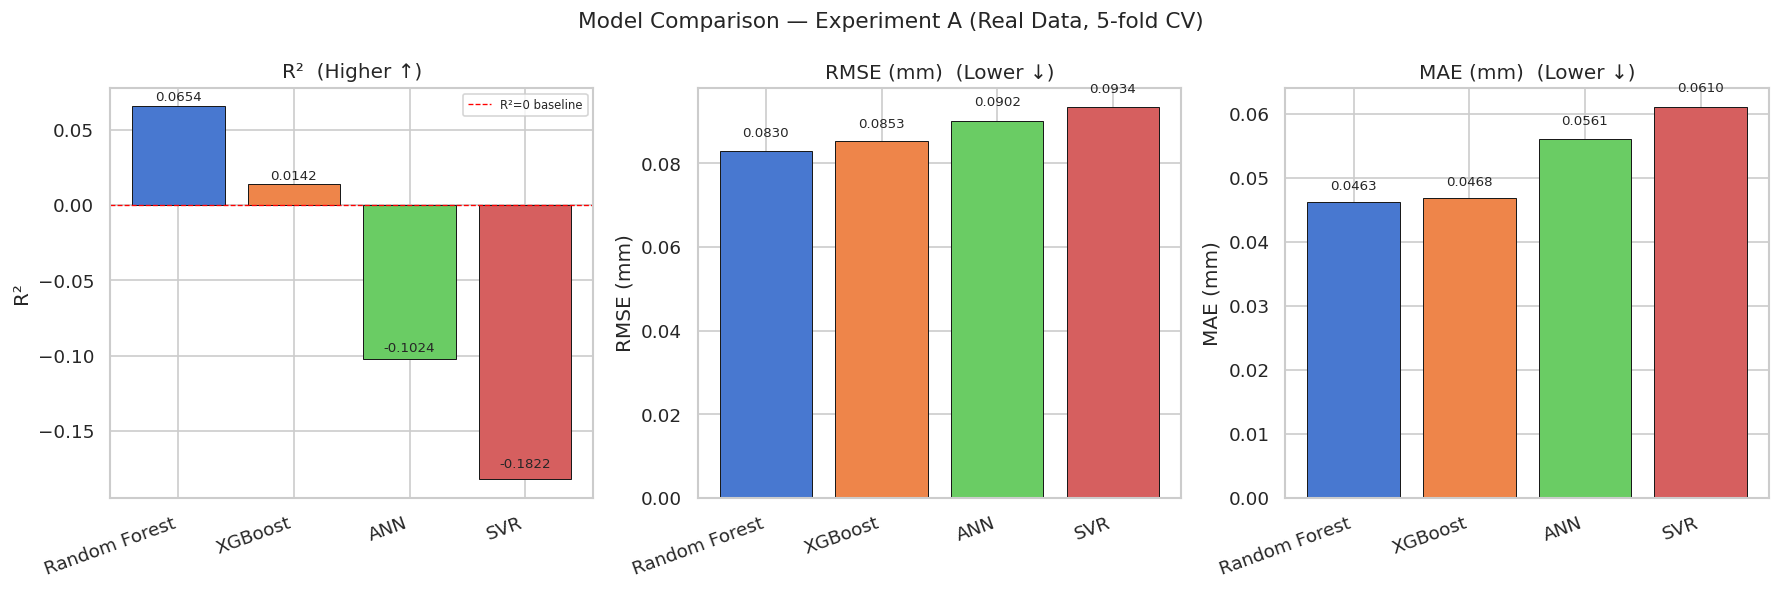

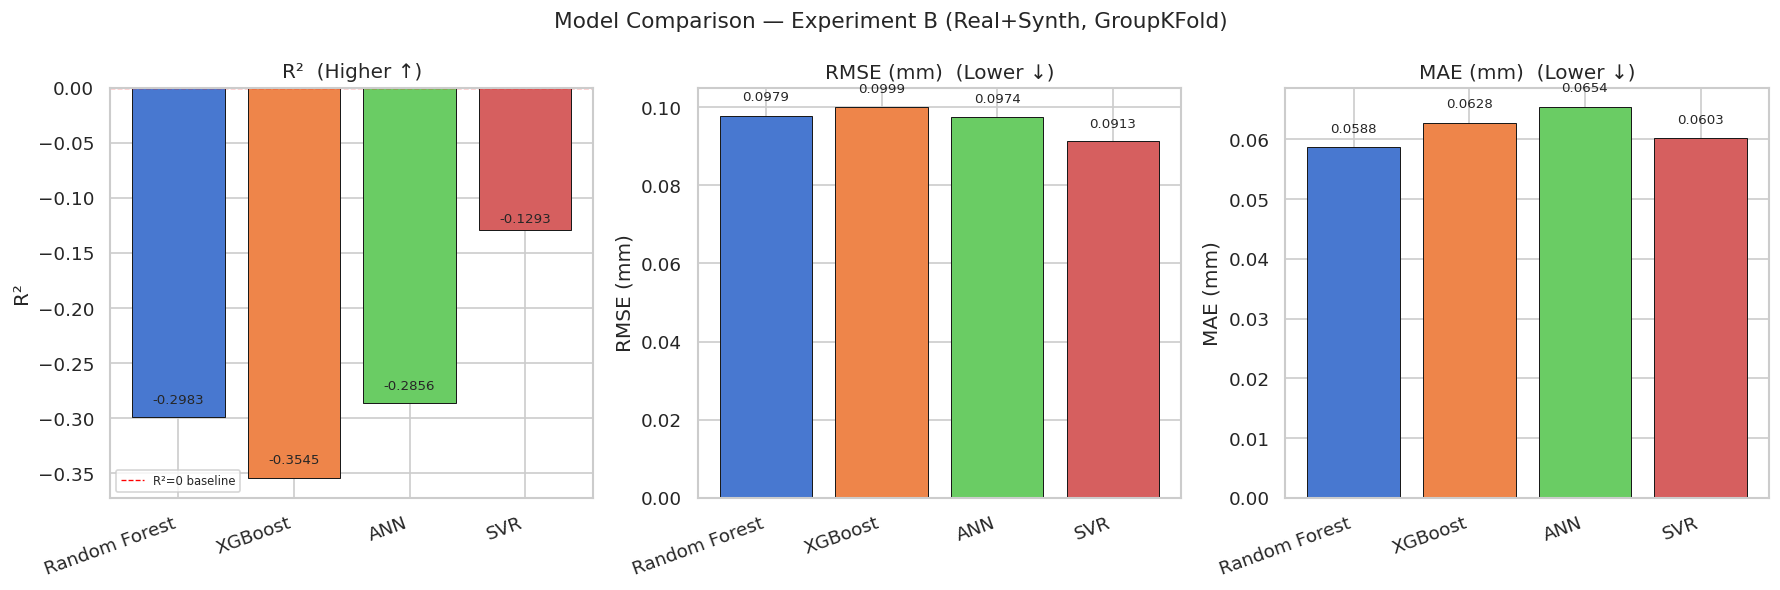

In [ ]:
# ── Comparison bar charts ─────────────────────────────────────────────────────
def plot_comparison(df_res, title_suffix, fig_name):
    model_names = df_res['Model'].tolist()
    x = np.arange(len(model_names))
    colors = sns.color_palette('muted', 4)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, (metric, unit, better) in zip(axes, [
        ('R²',       '',   'Higher ↑'),
        ('RMSE (mm)', 'mm', 'Lower ↓'),
        ('MAE (mm)',  'mm', 'Lower ↓')
    ]):
        bars = ax.bar(x, df_res[metric], color=colors, edgecolor='k', linewidth=0.6)
        ax.set_xticks(x)
        ax.set_xticklabels(model_names, rotation=20, ha='right')
        ax.set_ylabel(f'{metric}' if not unit else f'{metric}')
        ax.set_title(f'{metric}  ({better})')
        for bar, val in zip(bars, df_res[metric]):
            ypos = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2,
                    ypos + abs(ypos)*0.03 + 0.0001,
                    f'{val:.4f}', ha='center', va='bottom', fontsize=8)
        if metric == 'R²':
            ax.axhline(0, color='red', linestyle='--', linewidth=0.8, label='R²=0 baseline')
            ax.legend(fontsize=7)

    plt.suptitle(f'Model Comparison — {title_suffix}', fontsize=13)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / fig_name, bbox_inches='tight')
    plt.show()

plot_comparison(df_res_A, 'Experiment A (Real Data, 5-fold CV)', 'fig6_comparison_expA.png')
plot_comparison(df_res_B, 'Experiment B (Real+Synth, GroupKFold)', 'fig7_comparison_expB.png')

---
# Section 11: Actual vs Predicted Kerf Width
<a id='section11'></a>

For each model, we plot actual kerf width (x-axis) against predicted kerf width (y-axis).

- **Red dashed line** = perfect prediction (predicted = actual).
- Points **above** the line → model over-predicts.
- Points **below** the line → model under-predicts.
- These are **out-of-fold predictions** from Experiment A.

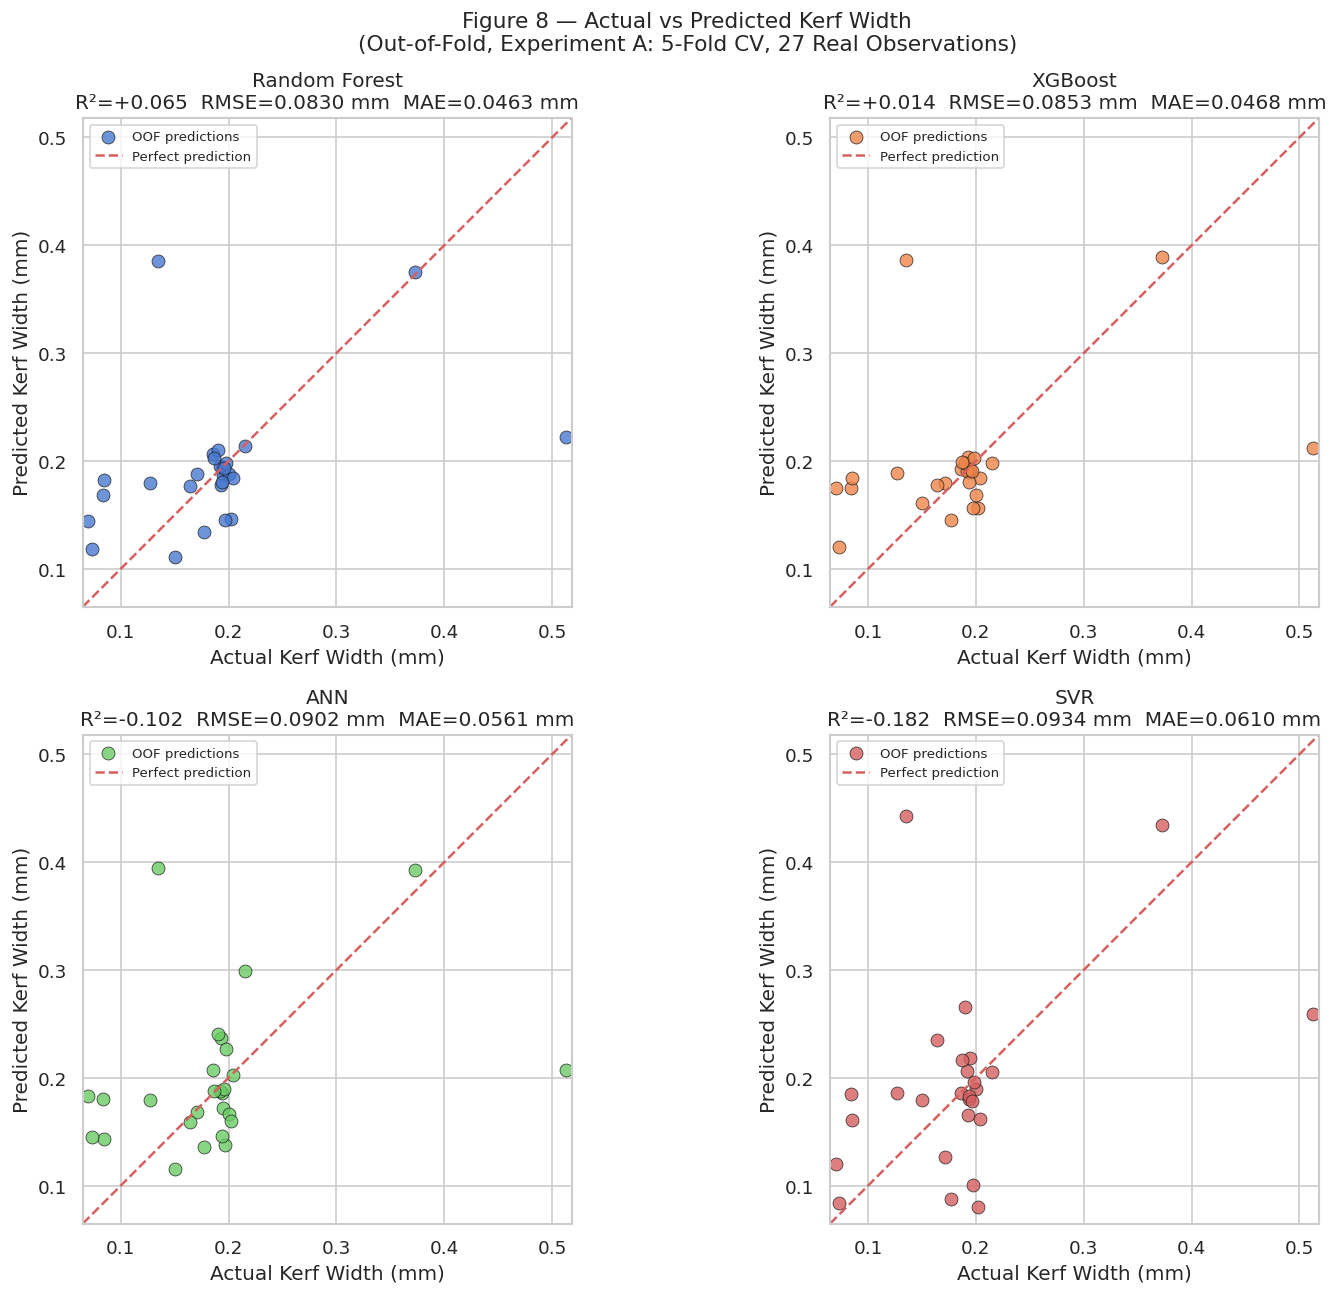

Interpretation: Points tightly clustered along the red diagonal indicate accurate predictions.
Each point was predicted by a model that had NOT seen that observation during training.


In [ ]:
# ── Figure 8: Actual vs Predicted — 2×2 panel ─────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 11))
axes = axes.flatten()
y_min = y_real.min() - 0.005
y_max = y_real.max() + 0.005

for i, name in enumerate(MODEL_BUILDERS):
    ax  = axes[i]
    oof = oof_preds_A[name]
    m   = results_A[name]

    ax.scatter(y_real, oof, alpha=0.8, s=60,
               color=sns.color_palette('muted')[i],
               edgecolors='k', linewidths=0.5, label='OOF predictions')
    ax.plot([y_min, y_max], [y_min, y_max],
            'r--', linewidth=1.5, label='Perfect prediction')
    ax.set_xlim(y_min, y_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel('Actual Kerf Width (mm)')
    ax.set_ylabel('Predicted Kerf Width (mm)')
    ax.set_title(
        f'{name}\n'
        f'R²={m["R2"]:+.3f}  RMSE={m["RMSE_mm"]:.4f} mm  MAE={m["MAE_mm"]:.4f} mm')
    ax.legend(fontsize=8)
    ax.set_aspect('equal')

plt.suptitle(
    'Figure 8 — Actual vs Predicted Kerf Width\n'
    '(Out-of-Fold, Experiment A: 5-Fold CV, 27 Real Observations)',
    fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig8_actual_vs_predicted.png', bbox_inches='tight')
plt.show()
print('Interpretation: Points tightly clustered along the red diagonal indicate accurate predictions.')
print('Each point was predicted by a model that had NOT seen that observation during training.')

---
# Section 12: Residual Analysis
<a id='section12'></a>

Residual = Actual − Predicted.  
**Ideal residuals** are randomly scattered around zero with no systematic trend.  
Performed for all four models; residuals saved for the best-performing model.

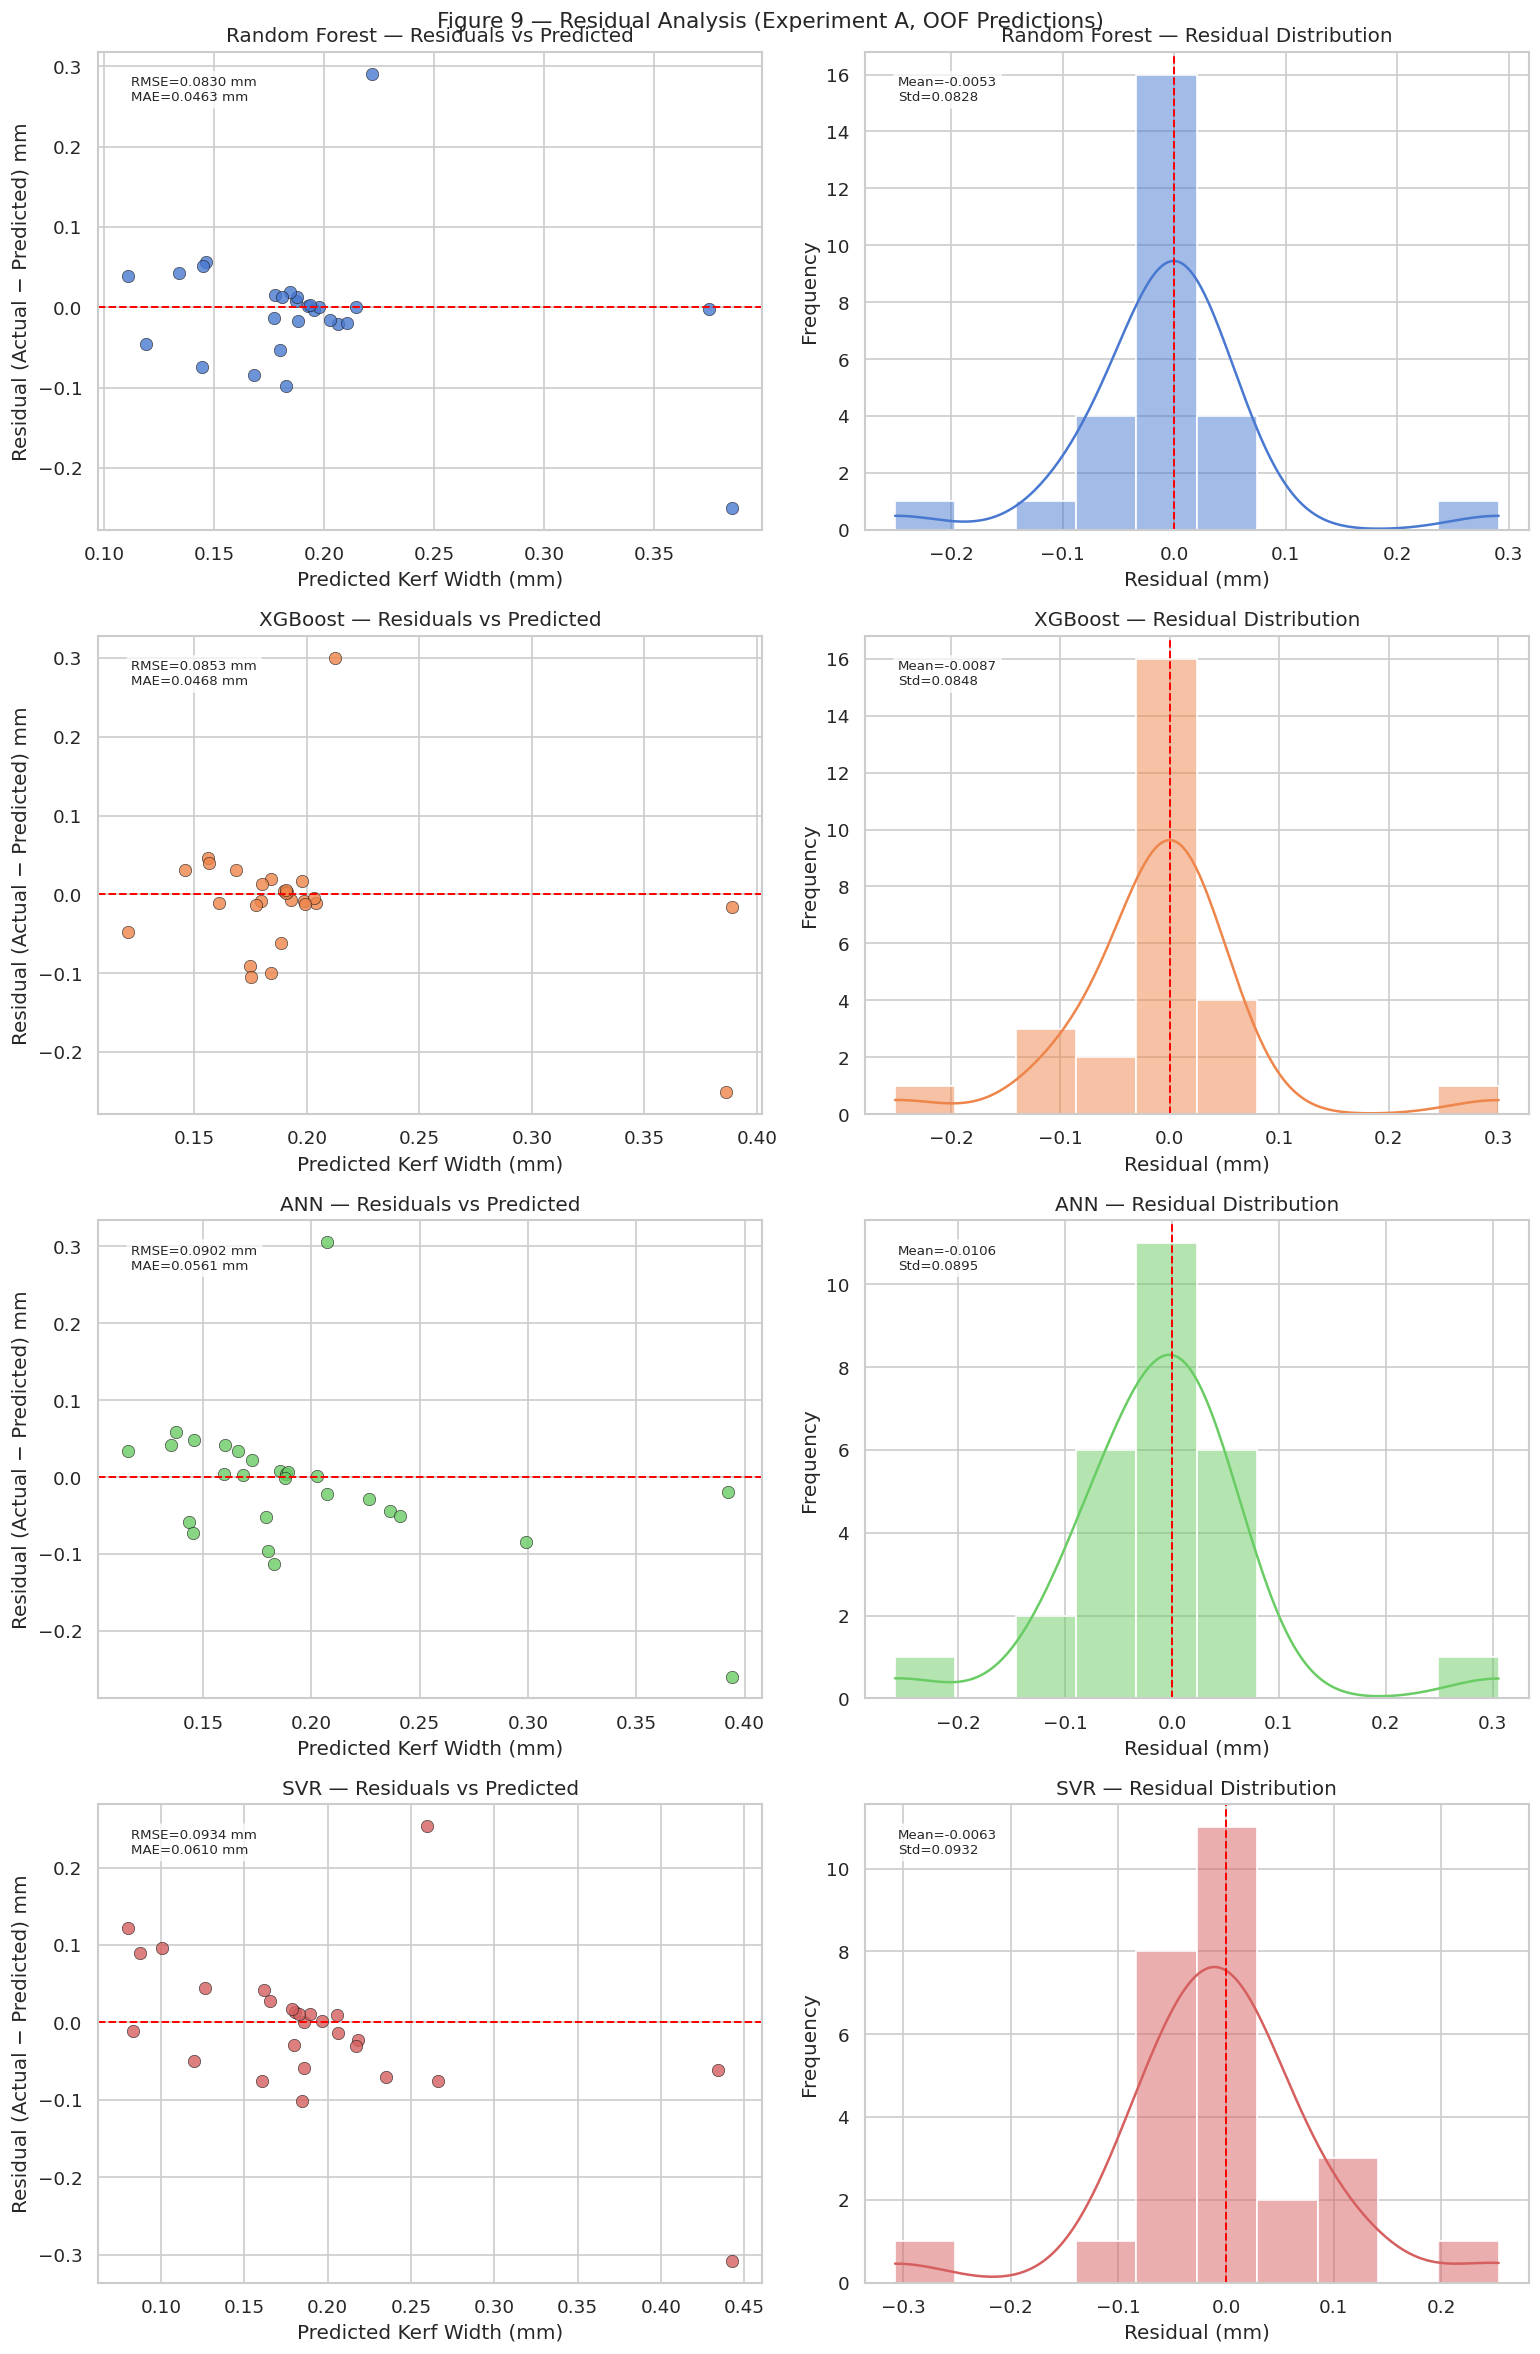

Residual Summary (Experiment A):


,Model,Mean Residual (mm),Std Residual (mm),Max Overpredict (mm),Max Underpredict (mm)
0,Random Forest,-0.005324,0.082849,0.250250,0.291095
1,XGBoost,-0.008652,0.084824,0.251215,0.300467
2,ANN,-0.010601,0.089543,0.259199,0.305716
3,SVR,-0.006278,0.093162,0.307634,0.253498



Mean residual ≈ 0 → no systematic bias. |Mean| >> 0 → systematic error.
⚠️  With only 27 observations, avoid over-interpreting residual patterns.


In [ ]:
# ── Figure 9: Residual plots for all four models ──────────────────────────────
fig, axes = plt.subplots(4, 2, figsize=(13, 20))

for i, name in enumerate(MODEL_BUILDERS):
    oof   = oof_preds_A[name]
    resid = y_real - oof
    m     = results_A[name]

    # Residuals vs Predicted
    ax_l = axes[i][0]
    ax_l.scatter(oof, resid, alpha=0.8, s=55,
                 color=sns.color_palette('muted')[i],
                 edgecolors='k', linewidths=0.4)
    ax_l.axhline(0, color='red', linestyle='--', linewidth=1.2)
    ax_l.set_xlabel('Predicted Kerf Width (mm)')
    ax_l.set_ylabel('Residual (Actual − Predicted) mm')
    ax_l.set_title(f'{name} — Residuals vs Predicted')
    ax_l.text(0.05, 0.95,
              f'RMSE={m["RMSE_mm"]:.4f} mm\nMAE={m["MAE_mm"]:.4f} mm',
              transform=ax_l.transAxes, va='top', fontsize=8,
              bbox=dict(boxstyle='round', fc='white', alpha=0.7))

    # Residual distribution
    ax_r = axes[i][1]
    sns.histplot(resid, bins=10, kde=True, ax=ax_r,
                 color=sns.color_palette('muted')[i])
    ax_r.axvline(0, color='red', linestyle='--', linewidth=1.2)
    ax_r.set_xlabel('Residual (mm)')
    ax_r.set_ylabel('Frequency')
    ax_r.set_title(f'{name} — Residual Distribution')
    ax_r.text(0.05, 0.95,
              f'Mean={np.mean(resid):.4f}\nStd={np.std(resid):.4f}',
              transform=ax_r.transAxes, va='top', fontsize=8,
              bbox=dict(boxstyle='round', fc='white', alpha=0.7))

plt.suptitle('Figure 9 — Residual Analysis (Experiment A, OOF Predictions)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig9_residuals.png', bbox_inches='tight')
plt.show()

# ── Residual summary table ────────────────────────────────────────────────────
print('Residual Summary (Experiment A):')
resid_rows = []
for name in MODEL_BUILDERS:
    r = y_real - oof_preds_A[name]
    resid_rows.append({
        'Model': name,
        'Mean Residual (mm)':    round(float(np.mean(r)), 6),
        'Std Residual (mm)':     round(float(np.std(r)),  6),
        'Max Overpredict (mm)':  round(float((-r).clip(min=0).max()), 6),
        'Max Underpredict (mm)': round(float(r.clip(min=0).max()), 6),
    })
display(pd.DataFrame(resid_rows))
print('\nMean residual ≈ 0 → no systematic bias. |Mean| >> 0 → systematic error.')
print('⚠️  With only 27 observations, avoid over-interpreting residual patterns.')

---
# Section 13: Feature Importance and Interpretation
<a id='section13'></a>

### Methods
- **RF / XGBoost:** Built-in impurity-based importance.
- **All four models:** Permutation importance (model-agnostic).

> ⚠️ **Limitations:** With 27 rows, importance estimates are noisy and dataset-specific. High importance does NOT prove a feature is a physical cause of kerf-width change. Impurity-based importance can overestimate high-cardinality features. Correlated features may split importance in misleading ways.

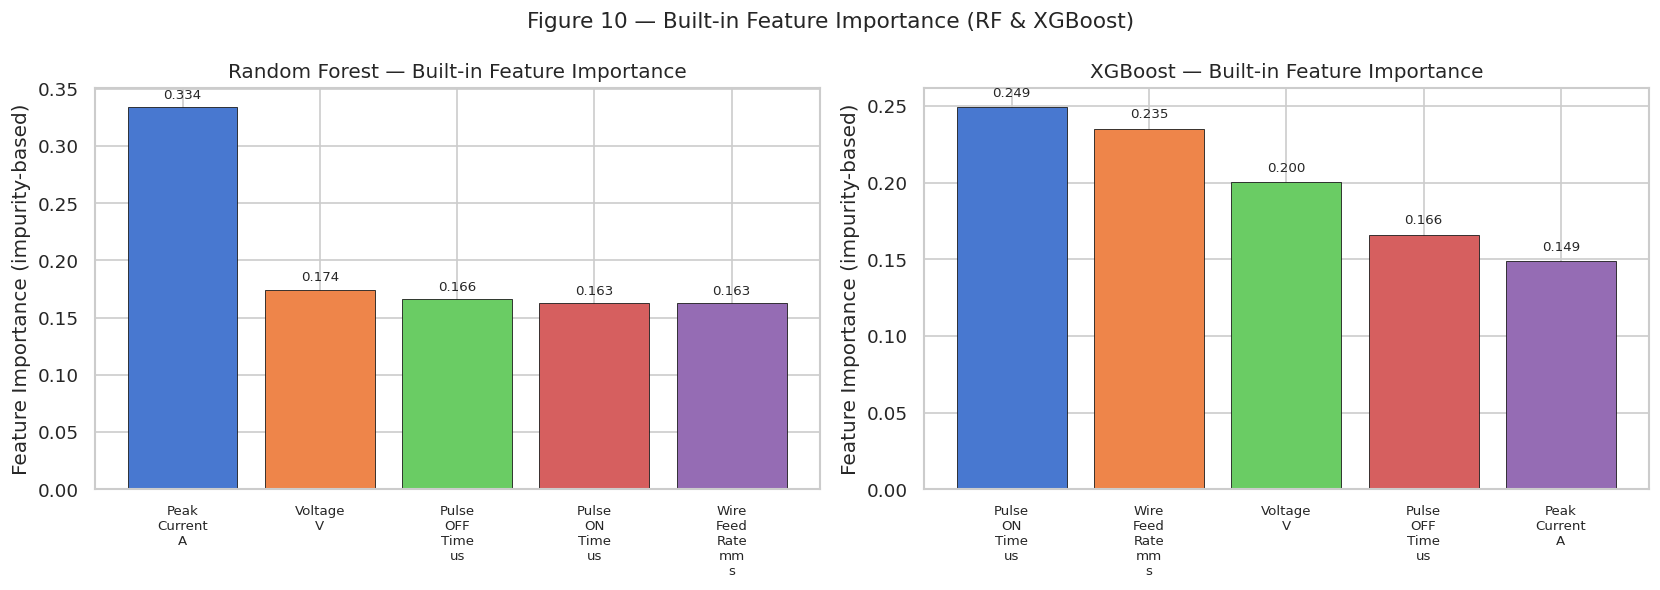

In [ ]:
# ── Figure 10: Built-in importance (RF & XGBoost) ─────────────────────────────
feature_labels = [c.replace('_', '\n') for c in FEATURE_COLS]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, name in zip(axes, ['Random Forest', 'XGBoost']):
    importances = tuned_models[name].named_steps['model'].feature_importances_
    sorted_idx  = np.argsort(importances)[::-1]
    bars = ax.bar(range(len(FEATURE_COLS)), importances[sorted_idx],
                  color=sns.color_palette('muted', len(FEATURE_COLS)),
                  edgecolor='k', linewidth=0.5)
    ax.set_xticks(range(len(FEATURE_COLS)))
    ax.set_xticklabels([feature_labels[i] for i in sorted_idx], rotation=0, fontsize=8)
    ax.set_ylabel('Feature Importance (impurity-based)')
    ax.set_title(f'{name} — Built-in Feature Importance')
    for bar, val in zip(bars, importances[sorted_idx]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)

plt.suptitle('Figure 10 — Built-in Feature Importance (RF & XGBoost)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig10_builtin_importance.png', bbox_inches='tight')
plt.show()

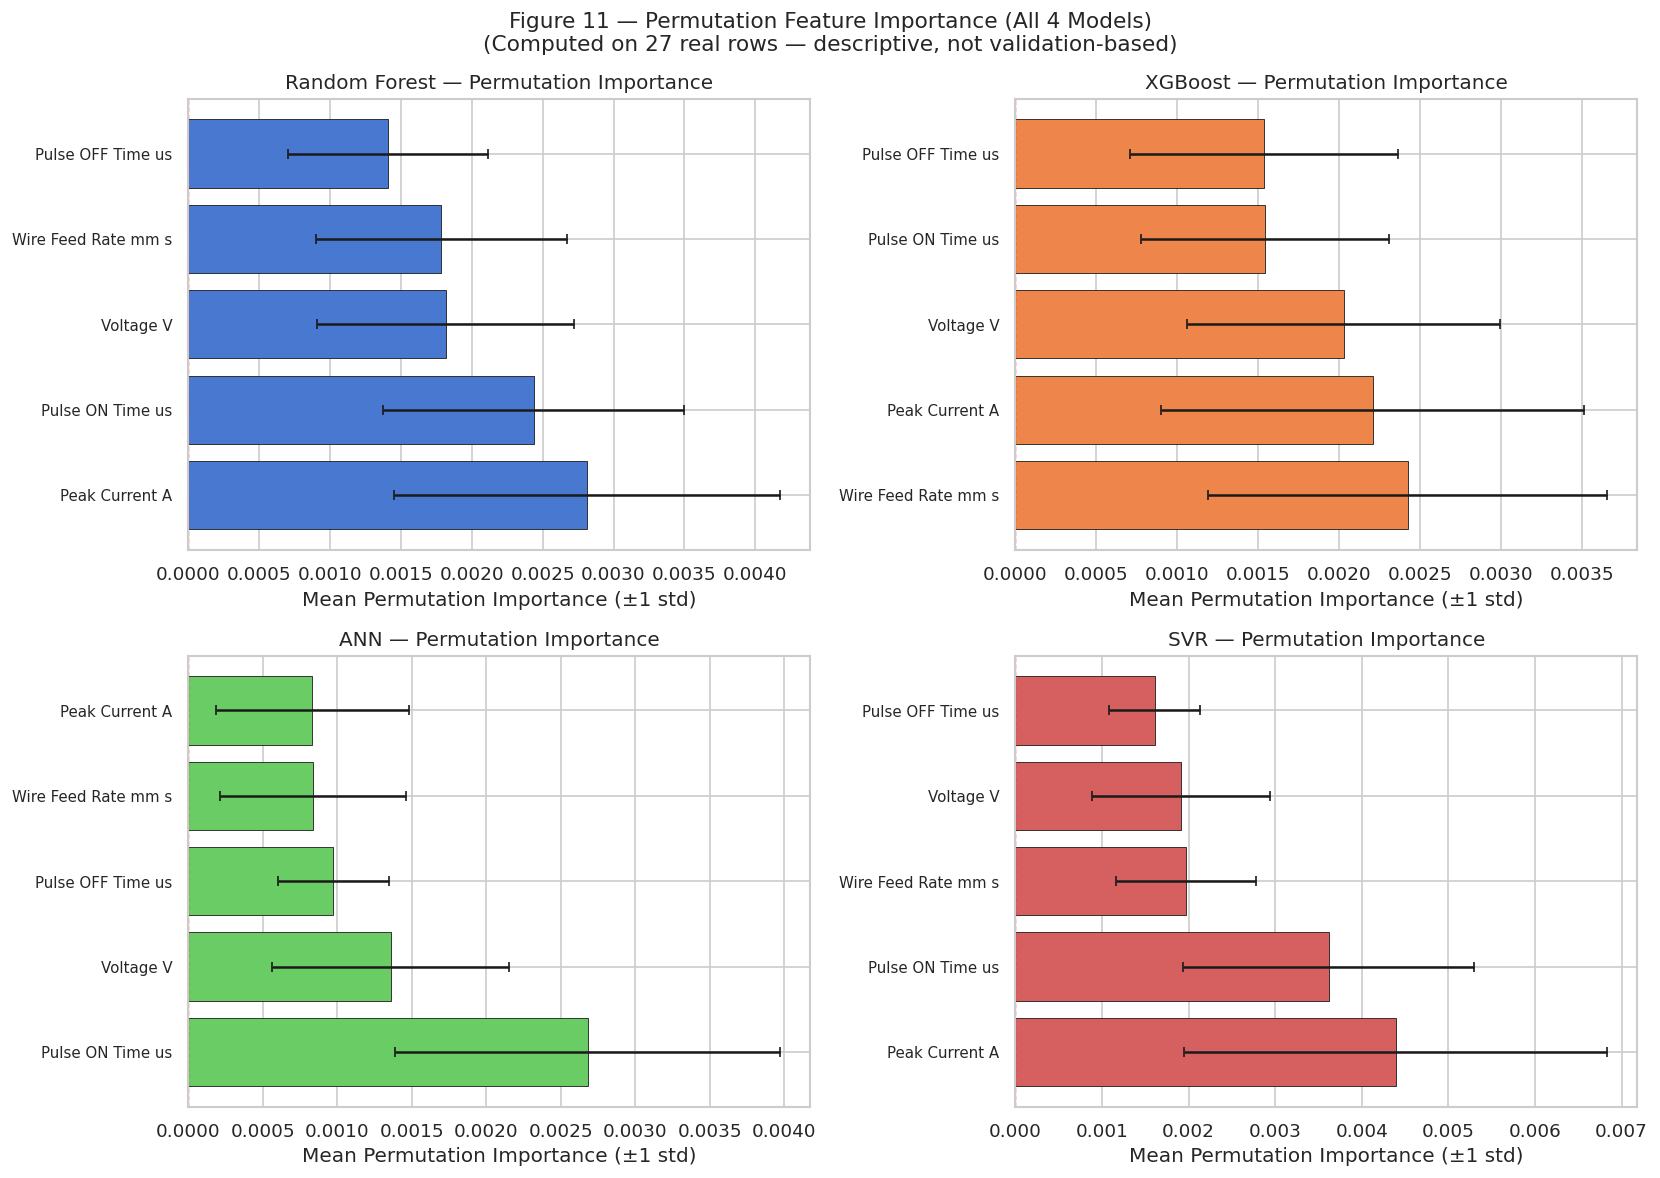

✅ Feature importance saved.
⚠️  These are exploratory results. Do not treat them as definitive causal evidence.


In [ ]:
# ── Figure 11: Permutation importance (all 4 models) ─────────────────────────
# Computed on all 27 real rows (descriptive — not validation-based)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()
perm_results = {}

for i, name in enumerate(MODEL_BUILDERS):
    perm = permutation_importance(
        tuned_models[name], X_real, y_real,
        n_repeats=30, random_state=RANDOM_SEED,
        scoring='neg_mean_squared_error'
    )
    perm_results[name] = perm
    sorted_idx = np.argsort(perm.importances_mean)[::-1]

    axes[i].barh(
        range(len(FEATURE_COLS)),
        perm.importances_mean[sorted_idx],
        xerr=perm.importances_std[sorted_idx],
        color=sns.color_palette('muted')[i],
        edgecolor='k', linewidth=0.5, capsize=3
    )
    axes[i].set_yticks(range(len(FEATURE_COLS)))
    axes[i].set_yticklabels(
        [FEATURE_COLS[j].replace('_', ' ') for j in sorted_idx], fontsize=9)
    axes[i].set_xlabel('Mean Permutation Importance (±1 std)')
    axes[i].set_title(f'{name} — Permutation Importance')
    axes[i].axvline(0, color='red', linestyle='--', linewidth=0.8)

plt.suptitle(
    'Figure 11 — Permutation Feature Importance (All 4 Models)\n'
    '(Computed on 27 real rows — descriptive, not validation-based)', fontsize=13)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'fig11_permutation_importance.png', bbox_inches='tight')
plt.show()

# Save permutation importance table
perm_rows = []
for name in MODEL_BUILDERS:
    perm = perm_results[name]
    for j, feat in enumerate(FEATURE_COLS):
        perm_rows.append({
            'Model': name, 'Feature': feat,
            'Perm_Importance_Mean': round(float(perm.importances_mean[j]), 6),
            'Perm_Importance_Std':  round(float(perm.importances_std[j]),  6),
        })
pd.DataFrame(perm_rows).to_csv(OUTPUT_DIR / 'feature_importance.csv', index=False)
print('✅ Feature importance saved.')
print('⚠️  These are exploratory results. Do not treat them as definitive causal evidence.')

---
# Section 14: Predict Kerf Width for New Machining Settings
<a id='section14'></a>

A reusable prediction function that:
1. Validates inputs against observed experimental ranges.
2. Issues an extrapolation warning for out-of-range inputs.
3. Uses the selected best model pipeline.
4. Returns predicted kerf width in mm.

> ⚠️ Output is a **model prediction**, not a measured machining result. Extrapolations (inputs outside observed ranges) may be unreliable.

In [ ]:
# ── Training data ranges ──────────────────────────────────────────────────────
PARAM_RANGES = {
    feat: {'min': float(df_real[feat].min()), 'max': float(df_real[feat].max())}
    for feat in FEATURE_COLS
}
print('Observed experimental ranges (27 real observations):')
for feat, rng in PARAM_RANGES.items():
    print(f'  {feat}: [{rng["min"]}, {rng["max"]}]')

# ── Prediction function ───────────────────────────────────────────────────────
def predict_kerf_width(
    wire_feed_rate_mm_s: float,
    voltage_V:           float,
    pulse_on_time_us:    float,
    pulse_off_time_us:   float,
    peak_current_A:      float,
    model_name:          str = None
) -> dict:
    """
    Predict kerf width for given WEDM machining parameters.
    Returns dict with 'predicted_kerf_width_mm', 'model_used', 'warnings'.
    """
    selected = model_name if (model_name and model_name in tuned_models) else best_model_name
    model    = tuned_models[selected]

    inputs    = [wire_feed_rate_mm_s, voltage_V, pulse_on_time_us,
                 pulse_off_time_us, peak_current_A]
    input_arr = np.array(inputs, dtype=float).reshape(1, -1)

    warnings_list = []
    for feat, val in zip(FEATURE_COLS, inputs):
        if val < 0:
            raise ValueError(f'{feat} cannot be negative. Received: {val}')
        rng = PARAM_RANGES[feat]
        if not (rng['min'] <= val <= rng['max']):
            warnings_list.append(
                f'  ⚠️  {feat} = {val} is outside training range '
                f'[{rng["min"]}, {rng["max"]}] — EXTRAPOLATION.')

    prediction = float(model.predict(input_arr)[0])

    if warnings_list:
        print('Extrapolation warnings:')
        for w in warnings_list:
            print(w)
        print('  Extrapolation predictions may be unreliable.')

    return {
        'predicted_kerf_width_mm': round(prediction, 6),
        'model_used': selected,
        'warnings': warnings_list
    }

print('\npredict_kerf_width() function defined.')

Observed experimental ranges (27 real observations):
  Wire_Feed_Rate_mm_s: [30.0, 50.0]
  Voltage_V: [40.0, 60.0]
  Pulse_ON_Time_us: [7.0, 9.0]
  Pulse_OFF_Time_us: [10.0, 12.0]
  Peak_Current_A: [2.0, 4.0]

predict_kerf_width() function defined.


In [ ]:
# ── Demo: predict at midpoint of observed ranges ──────────────────────────────
sample_input = {feat: (PARAM_RANGES[feat]['min'] + PARAM_RANGES[feat]['max']) / 2
                for feat in FEATURE_COLS}

print('Sample input (midpoint of observed ranges):')
for k, v in sample_input.items():
    print(f'  {k}: {v:.4f}')

result = predict_kerf_width(
    wire_feed_rate_mm_s = sample_input['Wire_Feed_Rate_mm_s'],
    voltage_V           = sample_input['Voltage_V'],
    pulse_on_time_us    = sample_input['Pulse_ON_Time_us'],
    pulse_off_time_us   = sample_input['Pulse_OFF_Time_us'],
    peak_current_A      = sample_input['Peak_Current_A']
)
print(f'\n📊 Prediction using [{result["model_used"]}]')
print(f'   Predicted Kerf Width : {result["predicted_kerf_width_mm"]:.6f} mm')
print('   (MODEL PREDICTION — not a measured machining result)')

print('\nPredictions from all four models for the same input:')
for mname in MODEL_BUILDERS:
    r = predict_kerf_width(
        wire_feed_rate_mm_s = sample_input['Wire_Feed_Rate_mm_s'],
        voltage_V           = sample_input['Voltage_V'],
        pulse_on_time_us    = sample_input['Pulse_ON_Time_us'],
        pulse_off_time_us   = sample_input['Pulse_OFF_Time_us'],
        peak_current_A      = sample_input['Peak_Current_A'],
        model_name          = mname
    )
    print(f'  {mname:20s}: {r["predicted_kerf_width_mm"]:.6f} mm')

Sample input (midpoint of observed ranges):
  Wire_Feed_Rate_mm_s: 40.0000
  Voltage_V: 50.0000
  Pulse_ON_Time_us: 8.0000
  Pulse_OFF_Time_us: 11.0000
  Peak_Current_A: 3.0000

📊 Prediction using [Random Forest]
   Predicted Kerf Width : 0.163940 mm
   (MODEL PREDICTION — not a measured machining result)

Predictions from all four models for the same input:
  Random Forest       : 0.163940 mm
  XGBoost             : 0.169236 mm
  ANN                 : 0.173867 mm
  SVR                 : 0.150493 mm


---
# Section 15: Save Model and Results
<a id='section15'></a>

All outputs are saved to `wedm_results/` and then zipped for download.

In [ ]:
# ── 1. Save all model pipelines ───────────────────────────────────────────────
for mname, mpipe in tuned_models.items():
    p = OUTPUT_DIR / f'model_{mname.replace(" ","_")}.joblib'
    joblib.dump(mpipe, p)
    print(f'✅ Saved: {p}')

best_model_path = OUTPUT_DIR / f'best_model_{best_model_name.replace(" ","_")}.joblib'
joblib.dump(tuned_models[best_model_name], best_model_path)
print(f'✅ Best model saved: {best_model_path}')

# ── 2. OOF predictions CSV ────────────────────────────────────────────────────
oof_df = df_real[[c for c in [ID_COL, TARGET_COL] + FEATURE_COLS if c in df_real.columns]].copy()
for mname in MODEL_BUILDERS:
    tag = mname.replace(' ', '_')
    oof_df[f'OOF_Pred_{tag}'] = oof_preds_A[mname]
    oof_df[f'Residual_{tag}'] = y_real - oof_preds_A[mname]
oof_df.to_csv(OUTPUT_DIR / 'oof_predictions.csv', index=False)
print('✅ OOF predictions CSV saved.')

# ── 3. Model comparison CSV ───────────────────────────────────────────────────
df_comparison.to_csv(OUTPUT_DIR / 'model_comparison.csv', index=False)
print('✅ Model comparison CSV saved.')

# ── 4. Metadata JSON ──────────────────────────────────────────────────────────
metadata = {
    'project': 'WEDM Kerf Width Prediction',
    'created': datetime.datetime.now().isoformat(),
    'best_model': best_model_name,
    'feature_names': FEATURE_COLS,
    'target_name': TARGET_COL,
    'n_real_observations': int(len(df_real)),
    'n_synthetic_observations': int((df[TYPE_COL]=='Synthetic_Interpolated').sum()),
    'training_methodology': {
        'experiment_A': '5-fold CV on 27 real observations',
        'experiment_B': f'{N_FOLDS_B}-fold GroupKFold on 45 rows, evaluated on real rows only'
    },
    'parameter_ranges': PARAM_RANGES,
    'best_hyperparameters': {k: str(v) for k, v in best_params[best_model_name].items()},
    'metrics_expA': results_A[best_model_name],
    'metrics_expB': results_B[best_model_name],
    'notes': [
        'Wire feed rate used (not wire tension).',
        'Synthetic observations are interpolated — not independent physical experiments.',
        'Metrics from 27 observations carry considerable sampling uncertainty.',
    ]
}
with open(OUTPUT_DIR / 'metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)
print('✅ Metadata JSON saved.')

print(f'\nAll outputs saved to: {OUTPUT_DIR.resolve()}')

✅ Saved: wedm_results/model_Random_Forest.joblib
✅ Saved: wedm_results/model_XGBoost.joblib
✅ Saved: wedm_results/model_ANN.joblib
✅ Saved: wedm_results/model_SVR.joblib
✅ Best model saved: wedm_results/best_model_Random_Forest.joblib
✅ OOF predictions CSV saved.
✅ Model comparison CSV saved.
✅ Metadata JSON saved.

All outputs saved to: /content/wedm_results


In [ ]:
# ── ZIP and download ──────────────────────────────────────────────────────────
zip_path = 'WEDM_Results.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in OUTPUT_DIR.iterdir():
        zf.write(f, arcname=f.name)

print(f'📦 Zipped all results to: {zip_path}')

if IN_COLAB:
    colab_files.download(zip_path)
    print('⬇️  Download started — check your browser downloads folder.')
else:
    print(f'Results folder: {OUTPUT_DIR.resolve()}')

📦 Zipped all results to: WEDM_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

⬇️  Download started — check your browser downloads folder.


---
# Section 16: Final Conclusion
<a id='section16'></a>

The conclusion below is **automatically generated from actual computed results** — no metric values are hardcoded.

In [ ]:
# ── Auto-generate conclusion ───────────────────────────────────────────────────
def ordinal(n):
    return {1:'1st', 2:'2nd', 3:'3rd'}.get(n, f'{n}th')

ranked_A_final = df_res_A.sort_values('RMSE (mm)').reset_index(drop=True)
best  = ranked_A_final.iloc[0]
worst = ranked_A_final.iloc[-1]

best_R2   = best['R²']
best_RMSE = best['RMSE (mm)']
best_MAE  = best['MAE (mm)']
mean_kw   = float(df_real[TARGET_COL].mean())
pct_error = 100 * best_RMSE / mean_kw

if best_RMSE < 0.01:
    error_comment = 'very close to typical WEDM measurement uncertainty, suggesting strong predictive accuracy within the observed parameter space'
elif best_RMSE < 0.05:
    error_comment = 'potentially acceptable for many WEDM applications, but further validation with additional experiments is recommended'
else:
    error_comment = 'non-trivial for precise WEDM applications; additional experimental data and model refinement are recommended before practical deployment'

r2_comment = (
    'a positive R², indicating the model explains some variance in kerf width'
    if best_R2 > 0 else
    'a NEGATIVE R², meaning predictions are worse than the mean-target baseline — '
    'the model has not generalised well, likely due to insufficient training data'
)

lines = [
    '=' * 70,
    'FINAL CONCLUSION — WEDM Kerf Width Prediction Project',
    '=' * 70,
    '',
    '1. OBJECTIVE',
    '   This project developed and compared four AI/ML regression models',
    '   (Random Forest, XGBoost, ANN, SVR) to predict kerf width in Wire',
    '   Electrical Discharge Machining from five machining parameters.',
    '',
    '2. DATASET COMPOSITION',
    f'   {len(df_real)} original experimental observations +',
    f'   {int((df[TYPE_COL]=="Synthetic_Interpolated").sum())} synthetic interpolated rows (total 45).',
    '   Synthetic rows were created by interpolating Peak Current while holding',
    '   other parameters constant — they are NOT independent experiments.',
    '',
    '3. BEST MODEL (Experiment A — Real Data Only, 5-Fold CV)',
    f'   ► {best["Model"]} achieved the lowest RMSE:',
    f'      R²   = {best_R2:+.4f}',
    f'      RMSE = {best_RMSE:.6f} mm  ({pct_error:.1f}% of mean kerf width)',
    f'      MAE  = {best_MAE:.6f} mm',
    f'   This RMSE is {error_comment}.',
    f'   The model shows {r2_comment}.',
    '',
    '4. MODEL RANKING (Experiment A, ascending RMSE):',
] + [
    f'   {ordinal(i+1)}: {row["Model"]:20s}  '
    f'R²={row["R²"]:+.4f}  RMSE={row["RMSE (mm)"]:.6f} mm  MAE={row["MAE (mm)"]:.6f} mm'
    for i, (_, row) in enumerate(ranked_A_final.iterrows())
] + [
    '',
    '5. LIMITATIONS',
    '   a) SMALL SAMPLE: 27 real observations produce high-variance CV estimates.',
    '      Small differences in RMSE between models may be within sampling noise.',
    '',
    '   b) SYNTHETIC DATA: 18 rows were interpolated, not physically measured.',
    '      They were excluded from all validation metric calculations.',
    '      Their benefit to model generalization cannot be confirmed without',
    '      independent test experiments.',
    '',
    '   c) EXTRAPOLATION: Model predictions outside the experimental parameter',
    '      ranges are unreliable and should not be used for machining decisions.',
    '',
    '   d) WIRE FEED RATE: This dataset uses wire feed rate rather than wire',
    '      tension. No tension column was fabricated or imputed.',
    '',
    '6. RECOMMENDATIONS',
    '   • Conduct ≥ 50–100 physical WEDM experiments using a formal DOE plan.',
    '   • Validate the model on a completely unseen experimental batch.',
    '   • Consider including wire tension if it can be measured.',
    '   • Explore physics-informed hybrid models.',
    '',
    '7. FINAL STATEMENT',
    f'   Based on the available data, {best["Model"]} showed the best generalisation',
    '   in Experiment A. However, given the small dataset, all four models should',
    '   be considered candidates pending validation with more real experiments.',
    '   This work demonstrates that AI/ML methods can model WEDM kerf width',
    '   relationships, but reliable industrial deployment requires a substantially',
    '   larger and independently validated experimental dataset.',
    '',
    '=' * 70,
]

conclusion_text = '\n'.join(lines)
print(conclusion_text)

with open(OUTPUT_DIR / 'final_conclusion.txt', 'w') as f:
    f.write(conclusion_text)
print('\n✅ Final conclusion saved to wedm_results/final_conclusion.txt')

FINAL CONCLUSION — WEDM Kerf Width Prediction Project

1. OBJECTIVE
   This project developed and compared four AI/ML regression models
   (Random Forest, XGBoost, ANN, SVR) to predict kerf width in Wire
   Electrical Discharge Machining from five machining parameters.

2. DATASET COMPOSITION
   27 original experimental observations +
   18 synthetic interpolated rows (total 45).
   Synthetic rows were created by interpolating Peak Current while holding
   other parameters constant — they are NOT independent experiments.

3. BEST MODEL (Experiment A — Real Data Only, 5-Fold CV)
   ► Random Forest achieved the lowest RMSE:
      R²   = +0.0654
      RMSE = 0.083020 mm  (44.3% of mean kerf width)
      MAE  = 0.046261 mm
   This RMSE is non-trivial for precise WEDM applications; additional experimental data and model refinement are recommended before practical deployment.
   The model shows a positive R², indicating the model explains some variance in kerf width.

4. MODEL RANKING (Exper

---

## 📌 Summary of Deliverables

| # | Deliverable | File |
|---|---|---|
| 1 | Best model pipeline | `best_model_<name>.joblib` |
| 2 | All four model pipelines | `model_<name>.joblib` |
| 3 | Model comparison table | `model_comparison.csv` |
| 4 | Out-of-fold predictions | `oof_predictions.csv` |
| 5 | Feature importance table | `feature_importance.csv` |
| 6 | Model metadata | `metadata.json` |
| 7 | Final conclusion | `final_conclusion.txt` |
| 8 | 11 figures (PNG) | `fig1_*` – `fig11_*` |
| 9 | ZIP archive | `WEDM_Results.zip` |

---

> **Reproducibility:** All random seeds are fixed to `42`. Re-running from top to bottom with the same CSV produces identical results.

---
*End of Notebook — WEDM Kerf Width Prediction | Non-Traditional Machining Project*